# ĐỀ TÀI: PHÂN TÍCH CHUỖI THỜI GIAN COVID-19 & XÂY DỰNG MÔ HÌNH DỰ BÁO CHO CÁC KHU VỰC BẮC MỸ, CHÂU Á & CHÂU PHI.

---

## 🎯 Mục tiêu bài học

# 1. Phân tích khám phá dữ liệu chuỗi thời gian (Time Series EDA)

- Xử lý dữ liệu theo thời gian: Chuẩn hóa cột ngày tháng, chuyển đổi sang kiểu DatetimeIndex và sắp xếp dữ liệu theo thứ tự thời gian.

- Tổng hợp dữ liệu theo châu lục: Tổng hợp số liệu COVID-19 theo ngày cho ba khu vực Bắc Mỹ, Châu Á và Châu Phi.

- Phân tích ca mắc mới và ca tích lũy: Tính tổng ca mắc tích lũy (Confirmed) và số ca mắc mới theo ngày (New_Confirmed).

- Làm mịn chuỗi thời gian: Tính trung bình trượt 7 ngày và 14 ngày (Rolling Average) nhằm quan sát xu hướng và giảm ảnh hưởng của biến động ngắn hạn.

- So sánh giữa các châu lục: Trực quan hóa và nhận xét sự khác biệt về xu hướng ca mắc mới, ca tích lũy và diễn biến dịch bệnh giữa ba khu vực.

- Phân tích dữ liệu bất thường: Xác định các thời điểm có biến động mạnh, dữ liệu thiếu hoặc số ca mắc mới âm do điều chỉnh số liệu nguồn.

# 2. Kỹ nghệ đặc trưng cho chuỗi thời gian (Time Series Feature Engineering)

- Tạo biến trễ (Lag Features): Xây dựng các biến Lag_1, Lag_2, Lag_3 và Lag_7 từ số ca mắc mới để sử dụng thông tin của những ngày trước trong dự báo.

- Tạo biến cửa sổ trượt (Rolling Window Statistics): Tính các thống kê theo cửa sổ thời gian, chẳng hạn trung bình trượt 7 ngày và 14 ngày.

- Tạo biến lịch (Calendar Features): Trích xuất các đặc trưng như DayOfWeek, Month và IsWeekend từ ngày quan sát.

- Xử lý tính không dừng (Non-stationarity): Khảo sát xu hướng của chuỗi thời gian và xem xét sai phân bậc 1 (First-order Differencing) khi phù hợp.

- Đảm bảo tính hợp lệ của đặc trưng: Tạo các biến đầu vào chỉ từ thông tin có sẵn tại thời điểm dự báo, hạn chế rò rỉ dữ liệu (Data Leakage).

# 3. Xây dựng mô hình dự báo và đánh giá (Forecasting Modeling & Evaluation)

- Phân chia dữ liệu theo thời gian (Temporal Split): Chia dữ liệu thành tập huấn luyện (Train) và tập kiểm tra (Test) theo thứ tự thời gian, không xáo trộn ngẫu nhiên (No Random Shuffle).

- Xây dựng và so sánh 5 mô hình hồi quy: Linear Regression, Ridge Regression, Random Forest Regressor, Gradient Boosting Regressor, Decision Tree Regressor

- Đánh giá hiệu suất mô hình: Sử dụng các chỉ số MAE (Mean Absolute Error), RMSE (Root Mean Squared Error), R² Score và MAPE (Mean Absolute Percentage Error).

- Trực quan hóa kết quả dự báo: So sánh số ca mắc mới thực tế với số ca dự báo trên tập kiểm tra của từng mô hình.

- Phân tích sai số (Residual Analysis): Đánh giá chênh lệch giữa giá trị thực tế và giá trị dự báo, xác định những giai đoạn mô hình dự báo chưa tốt.

- So sánh kết quả giữa các châu lục: Tổng hợp hiệu suất của các mô hình trên Bắc Mỹ, Châu Á và Châu Phi để nhận xét sự khác biệt về khả năng dự báo.

## 📌 Phạm vi và biến mục tiêu

- Phạm vi nghiên cứu: Bắc Mỹ, Châu Á và Châu Phi.

- Biến mục tiêu chính: Số ca mắc mới theo ngày (New_Confirmed).

- Biến dữ liệu hỗ trợ: Ca mắc tích lũy (Confirmed), tử vong tích lũy (Deaths), hồi phục tích lũy (Recovered) và ca đang hoạt động (Active), tùy theo dữ liệu thực tế và mục đích phân tích.

- Lưu ý về dữ liệu: Các cột Confirmed, Deaths, Recovered và Active trong dữ liệu đầu vào là số liệu tích lũy theo ngày. Do đó, New_Confirmed được tính bằng sai phân của tổng Confirmed giữa hai ngày liên tiếp. Ngày đầu tiên được gán giá trị 0 vì không có ngày trước đó để tính sai phân. Nếu xuất hiện số ca mới âm, cần giữ nguyên để phản ánh việc điều chỉnh dữ liệu từ nguồn, không tự động chuyển về 0 trong quá trình phân tích.


---

##  KHAI BÁO THƯ VIỆN VÀ CẤU HÌNH
**Yêu cầu**
- Chuẩn bị các thư viện phục vụ đọc, xử lý, phân tích và trực quan hóa dữ liệu.
- Khai báo các mô hình Machine Learning và chỉ số đánh giá.
- Thiết lập cấu hình chung để kết quả có thể tái lập.


In [2]:
# Nếu thiếu thư viện, bỏ dấu # ở dòng dưới rồi chạy một lần.
# %pip install numpy pandas matplotlib seaborn scikit-learn jinja2

import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import jinja2
from IPython.display import display

from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.labelsize"] = 11

print("Đã khai báo thư viện và cấu hình thành công.")
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Thư mục làm việc hiện tại:", Path.cwd())

Đã khai báo thư viện và cấu hình thành công.
Pandas: 3.0.6
NumPy: 2.5.4
Thư mục làm việc hiện tại: f:\covid19-time-series-ml\notebooks


## PHẦN 1. TỔNG QUAN VÀ TIỀN XỬ LÝ DỮ LIỆU
**Yêu cầu**
- Đọc 3 file CSV gốc.
- Kiểm tra kích thước, kiểu dữ liệu, khoảng ngày, giá trị thiếu và dòng trùng.
- Chuyển `Date` sang datetime và sắp xếp tăng dần.
- Cộng các cột tích lũy theo từng ngày trong từng châu lục.
- Tính `New_Confirmed`, `New_Deaths`, `New_Recovered` bằng sai phân.
- Lưu file tổng hợp và giải thích cách tính; không cộng các cột tích lũy qua nhiều ngày.


In [3]:
# PHẦN 1 - ĐỌC, KIỂM TRA VÀ TỔNG HỢP DỮ LIỆU COVID-19

# Hỗ trợ chạy notebook từ thư mục dự án hoặc từ thư mục notebooks/.
candidate_dirs = [
    Path.cwd() / "data",
    Path.cwd().parent / "data",
    Path.cwd(),
    Path.cwd().parent,
]
seen_dirs = set()
unique_dirs = []
for directory in candidate_dirs:
    if directory.exists():
        resolved_dir = str(directory.resolve())
        if resolved_dir not in seen_dirs:
            seen_dirs.add(resolved_dir)
            unique_dirs.append(directory)
candidate_dirs = unique_dirs

files = {
    "Bac My": "covid19_north_america.csv",
    "Chau A": "covid19_asia.csv",
    "Chau Phi": "covid19_africa.csv",
}
region_names = {
    "Bac My": "North America",
    "Chau A": "Asia",
    "Chau Phi": "Africa",
}

source_paths = None
for directory in candidate_dirs:
    found = {}
    for region, filename in files.items():
        exact_path = directory / filename
        if exact_path.is_file():
            found[region] = exact_path
        else:
            prefix = Path(filename).stem
            matches = sorted(directory.glob(f"{prefix}*.csv"))
            found[region] = matches[0] if matches else None
    if all(path is not None for path in found.values()):
        source_paths = found
        data_dir = directory
        break

if source_paths is None:
    expected = ", ".join(files.values())
    raise FileNotFoundError(
        f"Không tìm thấy đủ ba CSV nguồn ({expected}) trong thư mục data/ "
        "hoặc thư mục làm việc hiện tại/cấp cha."
    )

cumulative_cols = ["Confirmed", "Deaths", "Recovered", "Active"]
required_cols = ["Date", "Country/Region", *cumulative_cols]
datasets = {}
daily_parts = []
quality_rows = []

for region, path in source_paths.items():
    raw = pd.read_csv(path)
    missing_cols = [column for column in required_cols if column not in raw.columns]
    if missing_cols:
        raise ValueError(f"{path.name} thiếu các cột bắt buộc: {missing_cols}")

    original_rows = len(raw)
    duplicate_rows = int(raw.duplicated().sum())
    raw["Date"] = pd.to_datetime(raw["Date"], errors="coerce")
    invalid_dates = int(raw["Date"].isna().sum())
    raw = raw.dropna(subset=["Date"]).copy()
    if raw.empty:
        raise ValueError(f"{path.name} không còn dòng nào có ngày hợp lệ.")
    for column in cumulative_cols:
        raw[column] = pd.to_numeric(raw[column], errors="coerce")

    quality_rows.append({
        "Khu vực": region,
        "File": path.name,
        "Số dòng nguồn": original_rows,
        "Số cột": raw.shape[1],
        "Số quốc gia/vùng": raw["Country/Region"].nunique(),
        "Dòng trùng hoàn toàn": duplicate_rows,
        "Ngày không hợp lệ": invalid_dates,
        "Giá trị thiếu ở cột bắt buộc": int(raw[required_cols].isna().sum().sum()),
        "Ngày bắt đầu": raw["Date"].min(),
        "Ngày kết thúc": raw["Date"].max(),
    })
    datasets[region] = raw

    # Cộng số liệu tích lũy theo cùng ngày; không cộng dồn qua nhiều ngày.
    daily = (
        raw.groupby("Date")[cumulative_cols]
        .sum(min_count=1)
        .sort_index()
        .reset_index()
    )
    daily["Continent"] = region_names[region]
    daily["New_Confirmed"] = daily["Confirmed"].diff().fillna(0)
    daily["New_Deaths"] = daily["Deaths"].diff().fillna(0)
    daily["New_Recovered"] = daily["Recovered"].diff().fillna(0)
    daily["Rolling_7D_New_Confirmed"] = daily["New_Confirmed"].rolling(7, min_periods=1).mean()
    daily["Rolling_14D_New_Confirmed"] = daily["New_Confirmed"].rolling(14, min_periods=1).mean()
    daily["Cumulative_Confirmed_Total"] = daily["Confirmed"]
    daily_parts.append(daily)

quality_report = pd.DataFrame(quality_rows)
df_daily = (
    pd.concat(daily_parts, ignore_index=True)
    .sort_values(["Continent", "Date"])
    .reset_index(drop=True)
)
# Dùng tên df cho các bước EDA phía sau, như notebook 02.
df = df_daily

print("Thư mục chứa dữ liệu nguồn:", data_dir)
print("CHẤT LƯỢNG DỮ LIỆU NGUỒN")
display(quality_report)
print("Kích thước dữ liệu tổng hợp:", df_daily.shape)
print("Số dòng theo châu lục:")
display(df_daily.groupby("Continent").size().rename("Số dòng").reset_index())

# Kiểm tra khoảng trống ngày, sai lệch Active và số ca phát sinh âm.
continuity_rows = []
for continent, group in df_daily.groupby("Continent"):
    group = group.sort_values("Date")
    expected_dates = pd.date_range(group["Date"].min(), group["Date"].max(), freq="D")
    missing_dates = expected_dates.difference(group["Date"])
    active_expected = group["Confirmed"] - group["Deaths"] - group["Recovered"]
    active_mismatch = ~np.isclose(group["Active"], active_expected, equal_nan=True)
    continuity_rows.append({
        "Continent": continent,
        "Số ngày": len(group),
        "Ngày thiếu": len(missing_dates),
        "New_Confirmed âm": int((group["New_Confirmed"] < 0).sum()),
        "New_Deaths âm": int((group["New_Deaths"] < 0).sum()),
        "New_Recovered âm": int((group["New_Recovered"] < 0).sum()),
        "Active lệch công thức": int(active_mismatch.sum()),
    })
continuity_report = pd.DataFrame(continuity_rows)
print("KIỂM TRA CHUỖI THỜI GIAN VÀ GIÁ TRỊ BẤT THƯỜNG")
display(continuity_report)

negative_recovered = df_daily.loc[
    df_daily["New_Recovered"] < 0,
    ["Date", "Continent", "Recovered", "New_Recovered"],
].sort_values(["Continent", "Date"])
print("Các ngày có số ca hồi phục mới âm (nếu có):")
display(negative_recovered)
for _, row in negative_recovered.iterrows():
    mask = (
        (df_daily["Continent"] == row["Continent"])
        & df_daily["Date"].between(row["Date"] - pd.Timedelta(days=2), row["Date"] + pd.Timedelta(days=2))
    )
    print(f"Dữ liệu xung quanh ngày bất thường: {row['Continent']} - {row['Date'].date()}")
    display(df_daily.loc[mask, ["Date", "Recovered", "New_Recovered"]])
print("Các số ca phát sinh âm được giữ nguyên để phản ánh điều chỉnh từ dữ liệu tích lũy; không tự động đổi thành 0.")

# Kiểm tra phạm vi quốc gia và độ phủ ngày theo từng file nguồn.
from itertools import combinations

country_sets = {
    region: set(raw["Country/Region"].dropna().unique())
    for region, raw in datasets.items()
}
overlap_rows = []
for first, second in combinations(country_sets, 2):
    overlap_rows.append({
        "File 1": first,
        "File 2": second,
        "Số tên trùng": len(country_sets[first] & country_sets[second]),
        "Tên trùng": ", ".join(sorted(country_sets[first] & country_sets[second])),
    })
print("Tên quốc gia/vùng xuất hiện trong nhiều file (cần diễn giải theo quy tắc phân vùng):")
display(pd.DataFrame(overlap_rows))

coverage_rows = []
for region, raw in datasets.items():
    total_days = raw["Date"].nunique()
    country_days = raw.groupby("Country/Region")["Date"].nunique()
    for country, days in country_days.items():
        if days < total_days:
            coverage_rows.append({
                "Khu vực": region,
                "Quốc gia/vùng": country,
                "Số ngày có dữ liệu": int(days),
                "Số ngày thiếu": int(total_days - days),
            })
coverage_report = pd.DataFrame(coverage_rows)
print("ĐỘ PHỦ DỮ LIỆU THEO QUỐC GIA/VÙNG")
if coverage_report.empty:
    print("Không ghi nhận quốc gia/vùng nào thiếu ngày so với tổng số ngày của file khu vực.")
else:
    display(coverage_report.sort_values(["Khu vực", "Số ngày thiếu"], ascending=[True, False]))

# Đối chiếu các giá trị đã tổng hợp với file cũ nếu file đó có sẵn; không ghi đè file cũ.
existing_path = data_dir / "covid19_continent_daily_totals.csv"
if existing_path.exists():
    existing = pd.read_csv(existing_path)
    key_cols = ["Date", "Continent"]
    if set(key_cols + cumulative_cols).issubset(existing.columns):
        existing["Date"] = pd.to_datetime(existing["Date"], errors="coerce")
        merged = df_daily[key_cols + cumulative_cols].merge(
            existing[key_cols + cumulative_cols],
            on=key_cols,
            how="outer",
            suffixes=("_calculated", "_existing"),
            indicator=True,
        )
        comparison_rows = [
            {"Chỉ số": "Chỉ có trong dữ liệu vừa tính", "Số lượng": int((merged["_merge"] == "left_only").sum())},
            {"Chỉ số": "Chỉ có trong file tổng hợp cũ", "Số lượng": int((merged["_merge"] == "right_only").sum())},
        ]
        comparison_cols = cumulative_cols + [
            "New_Confirmed", "New_Deaths", "New_Recovered",
            "Rolling_7D_New_Confirmed", "Rolling_14D_New_Confirmed",
            "Cumulative_Confirmed_Total",
        ]
        for column in comparison_cols:
            if column not in existing.columns:
                continue
            values = df_daily[key_cols + [column]].merge(
                existing[key_cols + [column]], on=key_cols, how="outer", suffixes=("_calculated", "_existing")
            )
            mismatch = ~np.isclose(
                values[f"{column}_calculated"], values[f"{column}_existing"], equal_nan=True
            )
            comparison_rows.append({"Chỉ số": f"Dòng lệch {column}", "Số lượng": int(mismatch.sum())})
        print("ĐỐI CHIẾU VỚI FILE TỔNG HỢP CÓ SẴN")
        display(pd.DataFrame(comparison_rows))
    else:
        print("File tổng hợp cũ thiếu cột cần đối chiếu; bỏ qua so sánh.")
else:
    print("Không có file tổng hợp cũ để đối chiếu.")

output_path = data_dir / "covid19_continent_daily_totals_prepared.csv"
df_daily.to_csv(output_path, index=False, encoding="utf-8-sig")
print("Đã lưu dữ liệu đã chuẩn bị tại:", output_path)
print("Lưu ý: New_* được tính bằng sai phân số tích lũy; giá trị âm được giữ nguyên.")

Thư mục chứa dữ liệu nguồn: f:\covid19-time-series-ml\data
CHẤT LƯỢNG DỮ LIỆU NGUỒN


,Khu vực,File,Số dòng nguồn,Số cột,Số quốc gia/vùng,Dòng trùng hoàn toàn,Ngày không hợp lệ,Giá trị thiếu ở cột bắt buộc,Ngày bắt đầu,Ngày kết thúc
0,Bac My,covid19_north_america.csv,6580,10,24,0,0,0,2020-01-22,2020-07-27
1,Chau A,covid19_asia.csv,15040,10,48,0,0,0,2020-01-22,2020-07-27
2,Chau Phi,covid19_africa.csv,10340,10,55,0,0,0,2020-01-22,2020-07-27


Kích thước dữ liệu tổng hợp: (564, 12)
Số dòng theo châu lục:


,Continent,Số dòng
0,Africa,188
1,Asia,188
2,North America,188


KIỂM TRA CHUỖI THỜI GIAN VÀ GIÁ TRỊ BẤT THƯỜNG


...

Các số ca phát sinh âm được giữ nguyên để phản ánh điều chỉnh từ dữ liệu tích lũy; không tự động đổi thành 0.
Tên quốc gia/vùng xuất hiện trong nhiều file (cần diễn giải theo quy tắc phân vùng):


,File 1,File 2,Số tên trùng,Tên trùng
0,Bac My,Chau A,0,
1,Bac My,Chau Phi,0,
2,Chau A,Chau Phi,0,


ĐỘ PHỦ DỮ LIỆU THEO QUỐC GIA/VÙNG
Không ghi nhận quốc gia/vùng nào thiếu ngày so với tổng số ngày của file khu vực.
ĐỐI CHIẾU VỚI FILE TỔNG HỢP CÓ SẴN


,Chỉ số,Số lượng
0,Chỉ có trong dữ liệu vừa tính,0
1,Chỉ có trong file tổng hợp cũ,0
2,Dòng lệch Confirmed,0
3,Dòng lệch Deaths,0
4,Dòng lệch Recovered,0
5,Dòng lệch Active,0
6,Dòng lệch New_Confirmed,0
7,Dòng lệch New_Deaths,0
8,Dòng lệch New_Recovered,0
9,Dòng lệch Rolling_7D_New_Confirmed,0


Đã lưu dữ liệu đã chuẩn bị tại: f:\covid19-time-series-ml\data\covid19_continent_daily_totals_prepared.csv
Lưu ý: New_* được tính bằng sai phân số tích lũy; giá trị âm được giữ nguyên.


## PHẦN 2. PHÂN TÍCH KHÁM PHÁ DỮ LIỆU (TIME SERIES EDA)
**Yêu cầu tối thiểu**
1. Ca mắc mới theo ngày và trung bình trượt 7 ngày, 14 ngày.
2. Tổng ca xác nhận tích lũy theo thời gian.
3. So sánh tổng ca xác nhận, tử vong, hồi phục cuối kỳ giữa 3 châu lục.
4. Phân tích ngày trong tuần (nếu phù hợp với dữ liệu).
5. Bảng/biểu đồ ngày đạt đỉnh ca mắc mới cho mỗi châu lục.
6. Viết nhận xét cho từng hình; không chỉ đưa biểu đồ mà không diễn giải.


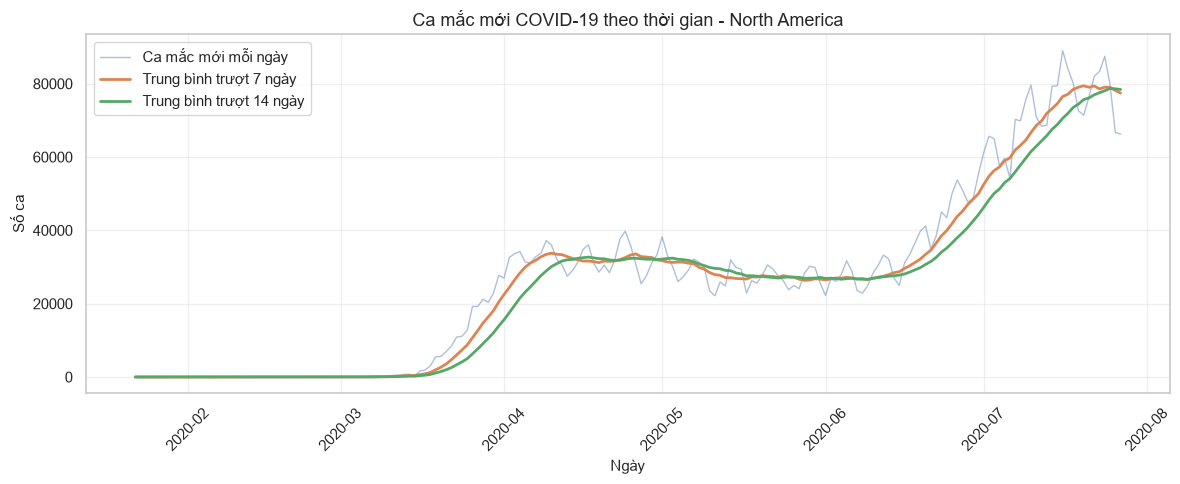

Nhận xét - North America: đỉnh quan sát được là 89,010 ca vào 2020-07-16. Trung bình trượt giúp làm rõ xu hướng; các giá trị âm do điều chỉnh dữ liệu vẫn được giữ nguyên.


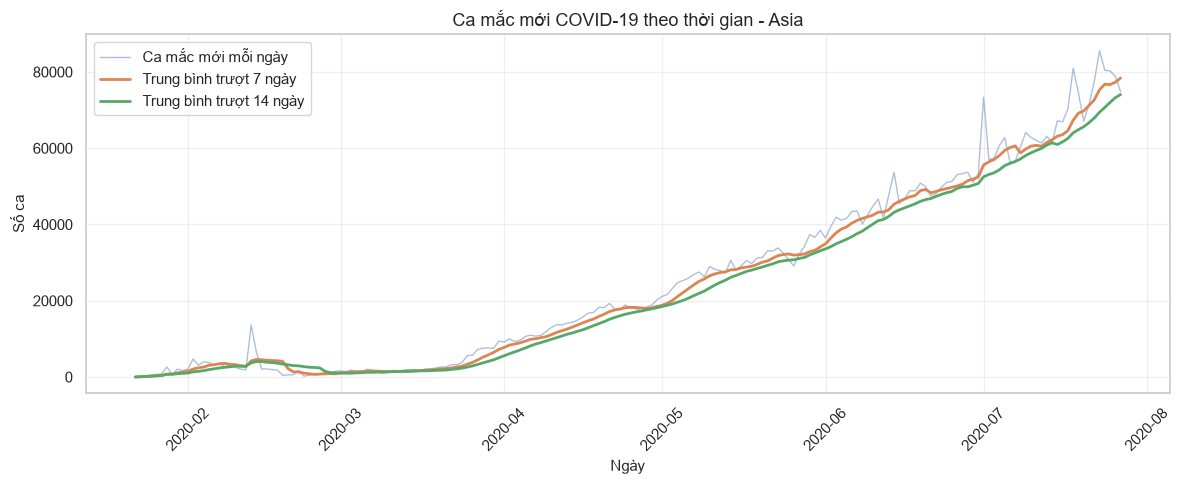

Nhận xét - Asia: đỉnh quan sát được là 85,583 ca vào 2020-07-23. Trung bình trượt giúp làm rõ xu hướng; các giá trị âm do điều chỉnh dữ liệu vẫn được giữ nguyên.


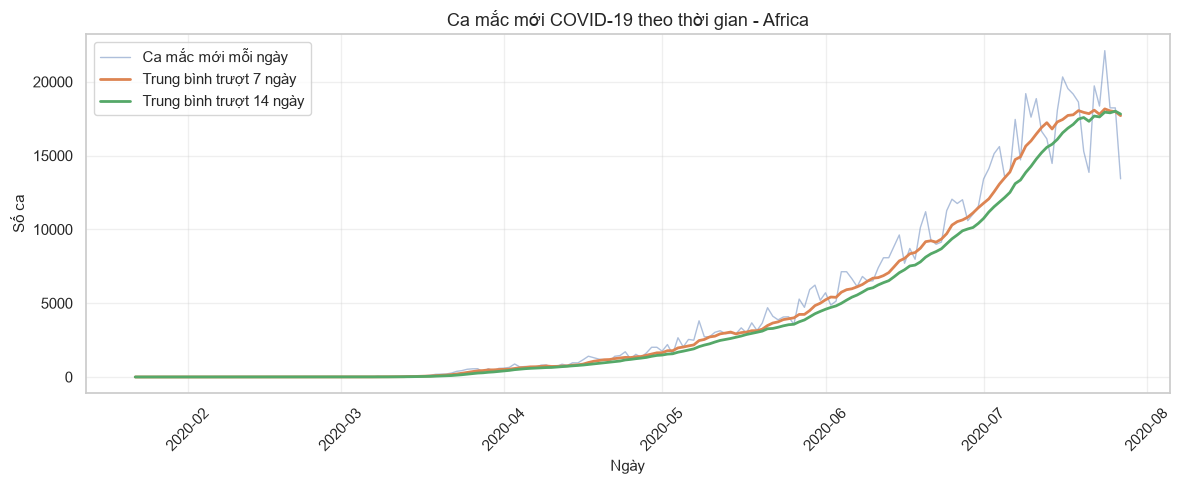

Nhận xét - Africa: đỉnh quan sát được là 22,111 ca vào 2020-07-24. Trung bình trượt giúp làm rõ xu hướng; các giá trị âm do điều chỉnh dữ liệu vẫn được giữ nguyên.


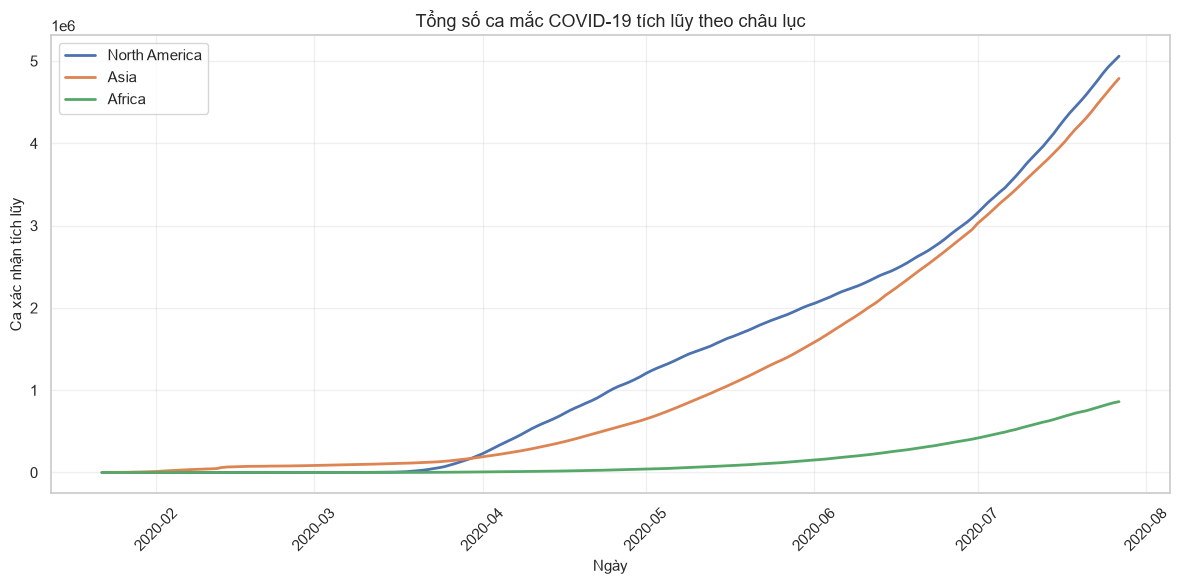

Nhận xét: số ca tuyệt đối mô tả quy mô tích lũy, không thể hiện nguy cơ tương đối nếu chưa chuẩn hóa theo dân số.
Thống kê cuối kỳ tại 2020-07-27:


,Continent,Confirmed,Deaths,Recovered,Active
0,North America,"5,058,816","207,226","1,754,456","3,097,134"
1,Asia,"4,788,295","104,469","3,473,508","1,210,318"
2,Africa,"860,537","18,176","506,229","336,132"


Nhận xét: North America có Confirmed tích lũy cao nhất (5,058,816); Asia có Recovered tích lũy cao nhất (3,473,508).
Ngày đạt đỉnh số ca mắc mới trong khoảng dữ liệu:


,Continent,Peak_Date,Peak_New_Confirmed
0,North America,2020-07-16 00:00:00,"89,010"
1,Asia,2020-07-23 00:00:00,"85,583"
2,Africa,2020-07-24 00:00:00,"22,111"


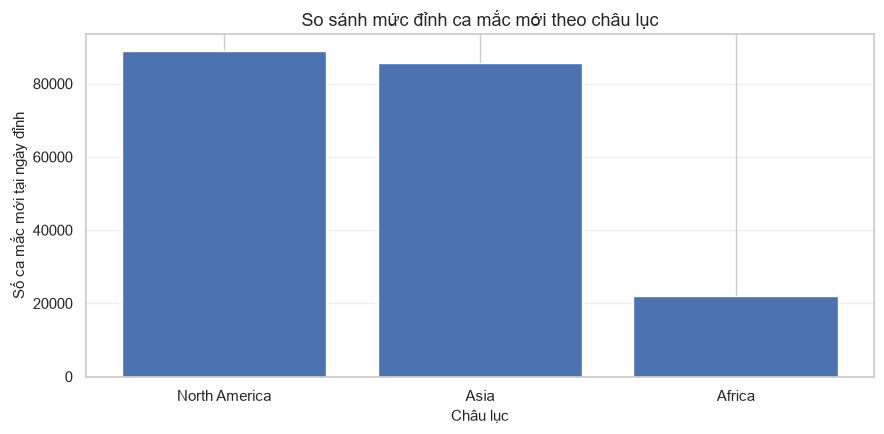

Nhận xét: đỉnh là mức cao nhất trong khoảng quan sát, không nhất thiết là đỉnh dịch thực tế.
Số ca mắc mới trung bình theo thứ trong tuần:


,Continent,Thứ trong tuần,Ca mắc mới trung bình
1,Africa,Thứ Hai,"4,414.37"
5,Africa,Thứ Ba,"3,955.58"
6,Africa,Thứ Tư,"4,384.89"
4,Africa,Thứ Năm,"4,750.48"
0,Africa,Thứ Sáu,"5,017.33"
2,Africa,Thứ Bảy,"4,915.30"
3,Africa,Chủ nhật,"4,580.30"
8,Asia,Thứ Hai,"25,197.00"
12,Asia,Thứ Ba,"24,110.46"
13,Asia,Thứ Tư,"24,874.89"


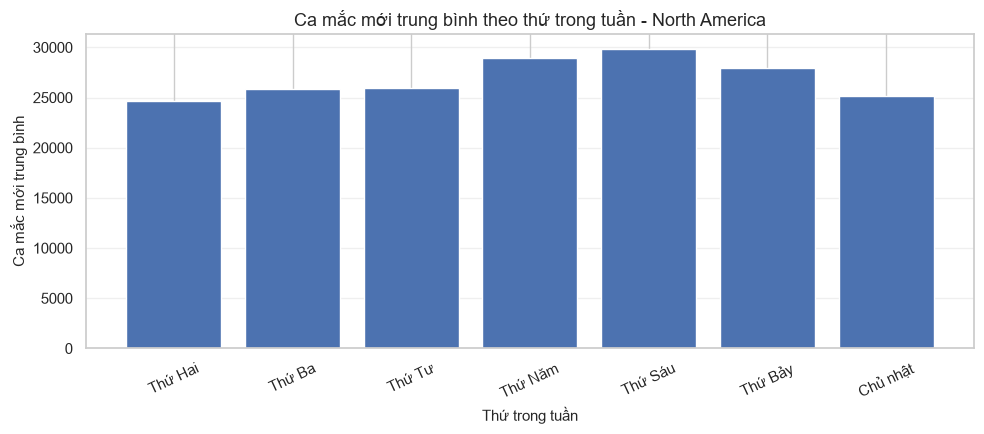

Nhận xét - North America: trung bình cao nhất vào Thứ Sáu (29,806.85) và thấp nhất vào Thứ Hai (24,660.33). Đây là mô tả thống kê, không chứng minh quan hệ nhân quả.


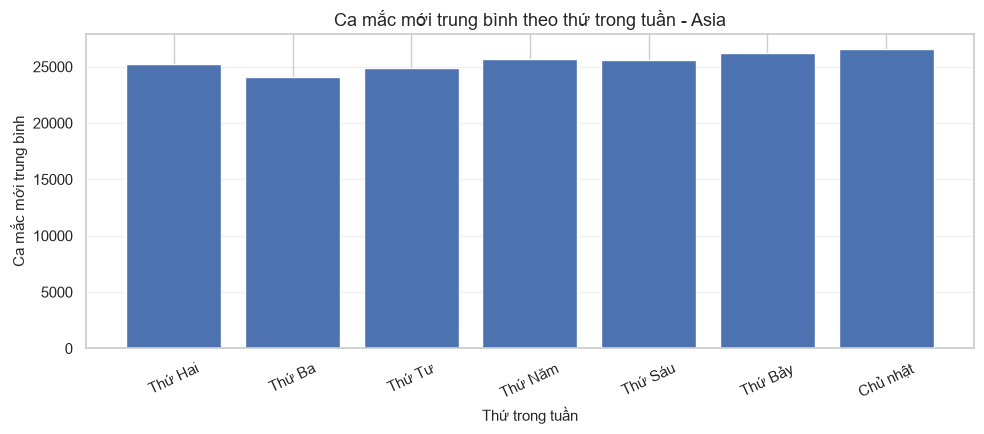

Nhận xét - Asia: trung bình cao nhất vào Chủ nhật (26,542.74) và thấp nhất vào Thứ Ba (24,110.46). Đây là mô tả thống kê, không chứng minh quan hệ nhân quả.


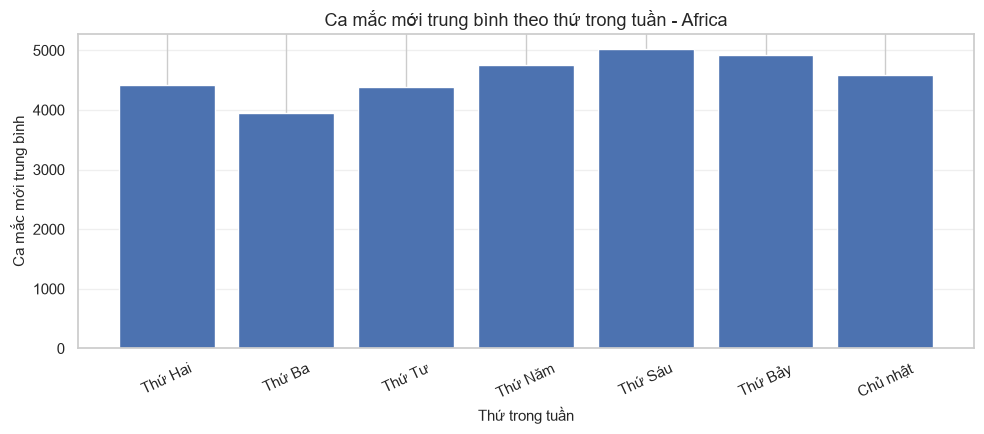

Nhận xét - Africa: trung bình cao nhất vào Thứ Sáu (5,017.33) và thấp nhất vào Thứ Ba (3,955.58). Đây là mô tả thống kê, không chứng minh quan hệ nhân quả.


In [4]:
# PHẦN 2 - TIME SERIES EDA

required_columns = [
    "Date", "Continent", "Confirmed", "Deaths", "Recovered", "Active",
    "New_Confirmed", "Rolling_7D_New_Confirmed", "Rolling_14D_New_Confirmed",
]
missing_columns = [column for column in required_columns if column not in df.columns]
if missing_columns:
    raise ValueError(f"Dữ liệu dùng cho EDA thiếu các cột bắt buộc: {missing_columns}")

continents = ["North America", "Asia", "Africa"]
weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
weekday_vietnamese = {
    "Monday": "Thứ Hai",
    "Tuesday": "Thứ Ba",
    "Wednesday": "Thứ Tư",
    "Thursday": "Thứ Năm",
    "Friday": "Thứ Sáu",
    "Saturday": "Thứ Bảy",
    "Sunday": "Chủ nhật",
}

# Ca mắc mới và trung bình trượt 7/14 ngày.
for continent in continents:
    temp = df.loc[df["Continent"] == continent].sort_values("Date").copy()
    if temp.empty:
        print(f"Không có dữ liệu cho {continent}; bỏ qua biểu đồ.")
        continue

    fig, ax = plt.subplots(figsize=(12, 5))
    ax.plot(temp["Date"], temp["New_Confirmed"], label="Ca mắc mới mỗi ngày", alpha=0.45, linewidth=1)
    ax.plot(temp["Date"], temp["Rolling_7D_New_Confirmed"], label="Trung bình trượt 7 ngày", linewidth=2)
    ax.plot(temp["Date"], temp["Rolling_14D_New_Confirmed"], label="Trung bình trượt 14 ngày", linewidth=2)
    ax.set_title(f"Ca mắc mới COVID-19 theo thời gian - {continent}")
    ax.set_xlabel("Ngày")
    ax.set_ylabel("Số ca")
    ax.legend()
    ax.grid(True, alpha=0.3)
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

    peak = temp.loc[temp["New_Confirmed"].idxmax()]
    print(
        f"Nhận xét - {continent}: đỉnh quan sát được là {int(peak['New_Confirmed']):,} ca "
        f"vào {peak['Date'].date()}. Trung bình trượt giúp làm rõ xu hướng; "
        "các giá trị âm do điều chỉnh dữ liệu vẫn được giữ nguyên."
    )

# Tổng số ca xác nhận tích lũy theo thời gian.
fig, ax = plt.subplots(figsize=(12, 6))
for continent in continents:
    temp = df.loc[df["Continent"] == continent].sort_values("Date")
    if not temp.empty:
        ax.plot(temp["Date"], temp["Confirmed"], label=continent, linewidth=2)
ax.set_title("Tổng số ca mắc COVID-19 tích lũy theo châu lục")
ax.set_xlabel("Ngày")
ax.set_ylabel("Ca xác nhận tích lũy")
ax.legend()
ax.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
print("Nhận xét: số ca tuyệt đối mô tả quy mô tích lũy, không thể hiện nguy cơ tương đối nếu chưa chuẩn hóa theo dân số.")

# So sánh số liệu tích lũy cuối kỳ.
latest_date = df["Date"].max()
latest_data = (
    df.loc[df["Date"] == latest_date, ["Continent", "Confirmed", "Deaths", "Recovered", "Active"]]
    .sort_values("Confirmed", ascending=False)
    .reset_index(drop=True)
)
print(f"Thống kê cuối kỳ tại {latest_date.date()}:")
display(latest_data.style.format({
    "Confirmed": "{:,.0f}",
    "Deaths": "{:,.0f}",
    "Recovered": "{:,.0f}",
    "Active": "{:,.0f}",
}))
if not latest_data.empty:
    highest_confirmed = latest_data.iloc[0]
    highest_recovered = latest_data.loc[latest_data["Recovered"].idxmax()]
    print(
        f"Nhận xét: {highest_confirmed['Continent']} có Confirmed tích lũy cao nhất "
        f"({highest_confirmed['Confirmed']:,.0f}); {highest_recovered['Continent']} "
        f"có Recovered tích lũy cao nhất ({highest_recovered['Recovered']:,.0f})."
    )

# Ngày và mức đỉnh ca mắc mới quan sát được trong từng châu lục.
peak_rows = []
for continent in continents:
    temp = df.loc[df["Continent"] == continent]
    if not temp.empty:
        peak = temp.loc[temp["New_Confirmed"].idxmax()]
        peak_rows.append({
            "Continent": continent,
            "Peak_Date": peak["Date"],
            "Peak_New_Confirmed": int(peak["New_Confirmed"]),
        })
peak_df = pd.DataFrame(peak_rows).sort_values("Peak_New_Confirmed", ascending=False).reset_index(drop=True)
print("Ngày đạt đỉnh số ca mắc mới trong khoảng dữ liệu:")
display(peak_df.style.format({"Peak_New_Confirmed": "{:,.0f}"}))
if not peak_df.empty:
    fig, ax = plt.subplots(figsize=(9, 4.5))
    ax.bar(peak_df["Continent"], peak_df["Peak_New_Confirmed"])
    ax.set_title("So sánh mức đỉnh ca mắc mới theo châu lục")
    ax.set_xlabel("Châu lục")
    ax.set_ylabel("Số ca mắc mới tại ngày đỉnh")
    ax.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()
    print("Nhận xét: đỉnh là mức cao nhất trong khoảng quan sát, không nhất thiết là đỉnh dịch thực tế.")

# Mô tả số ca mắc mới trung bình theo thứ trong tuần.
df["Weekday"] = df["Date"].dt.day_name()
weekday_avg = (
    df.groupby(["Continent", "Weekday"], as_index=False, observed=False)["New_Confirmed"]
    .mean()
)
weekday_avg["Weekday"] = pd.Categorical(weekday_avg["Weekday"], categories=weekday_order, ordered=True)
weekday_avg = weekday_avg.sort_values(["Continent", "Weekday"]).copy()
weekday_avg["Weekday_VI"] = weekday_avg["Weekday"].astype(str).map(weekday_vietnamese)
print("Số ca mắc mới trung bình theo thứ trong tuần:")
display(weekday_avg[["Continent", "Weekday_VI", "New_Confirmed"]].rename(columns={
    "Weekday_VI": "Thứ trong tuần",
    "New_Confirmed": "Ca mắc mới trung bình",
}).style.format({"Ca mắc mới trung bình": "{:,.2f}"}))

for continent in continents:
    temp = weekday_avg.loc[weekday_avg["Continent"] == continent]
    if temp.empty:
        continue
    fig, ax = plt.subplots(figsize=(10, 4.5))
    ax.bar(temp["Weekday_VI"], temp["New_Confirmed"])
    ax.set_title(f"Ca mắc mới trung bình theo thứ trong tuần - {continent}")
    ax.set_xlabel("Thứ trong tuần")
    ax.set_ylabel("Ca mắc mới trung bình")
    ax.grid(axis="y", alpha=0.3)
    plt.xticks(rotation=25)
    plt.tight_layout()
    plt.show()

    highest = temp.loc[temp["New_Confirmed"].idxmax()]
    lowest = temp.loc[temp["New_Confirmed"].idxmin()]
    print(
        f"Nhận xét - {continent}: trung bình cao nhất vào {highest['Weekday_VI']} "
        f"({highest['New_Confirmed']:,.2f}) và thấp nhất vào {lowest['Weekday_VI']} "
        f"({lowest['New_Confirmed']:,.2f}). Đây là mô tả thống kê, không chứng minh quan hệ nhân quả."
    )

In [5]:
 %pip install jinja2

Note: you may need to restart the kernel to use updated packages.


## PHẦN 3. KỸ NGHỆ ĐẶC TRƯNG (FEATURE ENGINEERING)
**Yêu cầu**
- Chọn `New_Confirmed` làm biến mục tiêu.
- Tạo sai phân bậc 1: `Diff_1 = New_Confirmed(t) - New_Confirmed(t-1)`.
- Tạo các biến trễ Lag 1, 2, 3, 7.
- Tạo thống kê cửa sổ trượt dựa trên quá khứ (ví dụ trung bình 7 ngày, độ lệch chuẩn 7 ngày).
- Tạo biến lịch như `DayOfWeek`, `IsWeekend` và/hoặc `Month`.
- Loại bỏ các dòng NaN do shift/rolling.
- Tránh rò rỉ dữ liệu tương lai: rolling features phải dùng dữ liệu đã shift(1).


In [6]:
# PHẦN 3 - FEATURE ENGINEERING
# Sử dụng df và continents đã có từ Phần 1–2 của notebook chính.
# Không đọc lại CSV hoặc tạo lại df/continents để tránh trùng biến giữa các notebook.

feature_input_columns = ["Date", "Continent", "New_Confirmed"]
missing_feature_columns = [col for col in feature_input_columns if col not in df.columns]
if missing_feature_columns:
    raise ValueError(f"Thiếu cột đầu vào cho Feature Engineering: {missing_feature_columns}")

feature_source = df[feature_input_columns].copy()
feature_source["Date"] = pd.to_datetime(feature_source["Date"], errors="coerce")
feature_source["New_Confirmed"] = pd.to_numeric(feature_source["New_Confirmed"], errors="coerce")
feature_source = feature_source.dropna(subset=feature_input_columns)
feature_source = feature_source.sort_values(["Continent", "Date"]).reset_index(drop=True)

# Dữ liệu chính cần có đúng một dòng cho mỗi ngày trong từng châu lục.
duplicate_daily_rows = int(feature_source.duplicated(["Continent", "Date"]).sum())
if duplicate_daily_rows:
    raise ValueError(f"Dữ liệu đầu vào có {duplicate_daily_rows} dòng trùng Continent-Date.")

# Các cấu hình/biến riêng của bước Feature Engineering; df, continents, np và pd
# được tái sử dụng từ notebook chính, không khai báo lại.
LAGS = [1, 2, 3, 7]
ROLL_WINDOW = 7
TARGET_LEVEL = "New_Confirmed"
TARGET_DIFF = "Diff_1"
FEATURES_ALL = [
    "Lag_1", "Lag_2", "Lag_3", "Lag_7",
    "Roll_Mean_7", "Roll_Std_7",
    "DayOfWeek", "IsWeekend", "Month",
]


def make_features(g):
    """Tạo target và feature cho một châu lục từ chuỗi New_Confirmed."""
    g = g[["Date", "Continent", "New_Confirmed"]].copy()
    g["Date"] = pd.to_datetime(g["Date"], errors="coerce")
    g["New_Confirmed"] = pd.to_numeric(g["New_Confirmed"], errors="coerce")
    g = g.dropna(subset=["Date", "New_Confirmed"])
    g = g.sort_values("Date").reset_index(drop=True)

    # Phần 1 điền 0 cho New_Confirmed của ngày đầu vì không có ngày trước đó.
    # Loại ngày đó theo quy ước đã nêu trong tài liệu thành viên 3.
    g = g.iloc[1:].reset_index(drop=True)
    y = g["New_Confirmed"]

    out = pd.DataFrame({
        "Date": g["Date"],
        "Continent": g["Continent"],
        TARGET_LEVEL: y,
        TARGET_DIFF: y.diff(),
    })

    # Các lag chỉ lấy giá trị từ những ngày trước đó.
    for lag in LAGS:
        out[f"Lag_{lag}"] = y.shift(lag)

    # Shift trước khi rolling để chỉ dùng y(t-1), ..., y(t-7), không dùng y(t).
    past_values = y.shift(1)
    out["Roll_Mean_7"] = past_values.rolling(window=ROLL_WINDOW, min_periods=ROLL_WINDOW).mean()
    out["Roll_Std_7"] = past_values.rolling(window=ROLL_WINDOW, min_periods=ROLL_WINDOW).std()

    # Biến lịch suy ra từ ngày quan sát, không dùng thông tin target tương lai.
    out["DayOfWeek"] = out["Date"].dt.dayofweek
    out["IsWeekend"] = (out["DayOfWeek"] >= 5).astype(int)
    out["Month"] = out["Date"].dt.month
    return out


# Tạo feature riêng từng châu lục, dùng danh sách continents từ Phần 2.
missing_continents = [c for c in continents if c not in set(feature_source["Continent"])]
if missing_continents:
    raise ValueError(f"Không tìm thấy dữ liệu cho các châu lục: {missing_continents}")

feat_raw = pd.concat(
    [make_features(feature_source.loc[feature_source["Continent"] == c]) for c in continents],
    ignore_index=True,
)
feat_raw = feat_raw.sort_values(["Continent", "Date"]).reset_index(drop=True)

# Kiểm tra thứ tự thời gian và thống kê số dòng NaN trước khi loại bỏ.
needed_cols = [TARGET_LEVEL, TARGET_DIFF] + FEATURES_ALL
nan_rows = []
for continent in continents:
    group = feat_raw.loc[feat_raw["Continent"] == continent].sort_values("Date")
    nan_rows.append({
        "Châu lục": continent,
        "Dòng sau khi bỏ ngày đầu": len(group),
        "Dòng có NaN do shift/rolling/sai phân": int(group[needed_cols].isna().any(axis=1).sum()),
        "Dòng đủ dữ liệu": int(group[needed_cols].notna().all(axis=1).sum()),
        "Ngày tăng dần": bool(group["Date"].is_monotonic_increasing),
        "Ngày trùng": int(group["Date"].duplicated().sum()),
    })
feature_quality_report = pd.DataFrame(nan_rows)
print("Kiểm tra dữ liệu trước khi loại NaN:")
display(feature_quality_report)

feat = (
    feat_raw.dropna(subset=needed_cols)
    .sort_values(["Continent", "Date"])
    .reset_index(drop=True)
)

# Kiểm tra đầu ra sau khi bỏ các dòng chưa đủ lịch sử.
if feat.empty:
    raise ValueError("Không còn dòng dữ liệu sau khi tạo lag/rolling và loại NaN.")
if feat.duplicated(["Continent", "Date"]).any():
    raise AssertionError("Bảng feature vẫn còn dòng trùng Continent-Date.")
if feat[needed_cols].isna().any().any():
    raise AssertionError("Bảng feature vẫn còn NaN sau khi xử lý.")
if not np.isfinite(feat[needed_cols].to_numpy(dtype=float)).all():
    raise AssertionError("Bảng feature có giá trị vô cực hoặc không hữu hạn.")
for continent in continents:
    group = feat.loc[feat["Continent"] == continent]
    if not group["Date"].is_monotonic_increasing:
        raise AssertionError(f"Ngày không tăng dần trong feature của {continent}.")

print("Kích thước trước khi loại NaN:", feat_raw.shape)
print("Kích thước feature cuối cùng:", feat.shape)
print("Tổng NaN ở target/features sau xử lý:", int(feat[needed_cols].isna().sum().sum()))
print("Tổng giá trị không hữu hạn ở target/features:", int((~np.isfinite(feat[needed_cols].to_numpy(dtype=float))).sum()))
print("Danh sách target và feature:")
print(" - Target Level:", TARGET_LEVEL)
print(" - Target Diff :", TARGET_DIFF)
print(" - Features    :", FEATURES_ALL)
display(feat.groupby("Continent").agg(
    So_dong=("Date", "size"),
    Tu_ngay=("Date", "min"),
    Den_ngay=("Date", "max"),
).reset_index())

# Kiểm tra chống rò rỉ dữ liệu: lag, rolling theo 7 ngày trước, perturbation và Diff.
leak_rows = []
rng = np.random.default_rng(RANDOM_STATE)
for continent in continents:
    group_source = feature_source.loc[feature_source["Continent"] == continent].sort_values("Date").reset_index(drop=True)
    group_feat = feat.loc[feat["Continent"] == continent].reset_index(drop=True)
    y_past = group_source.iloc[1:].set_index("Date")["New_Confirmed"]
    positions = y_past.index.get_indexer(group_feat["Date"])

    lag_ok = all(
        np.allclose(group_feat[f"Lag_{lag}"].to_numpy(), y_past.to_numpy()[positions - lag])
        for lag in LAGS
    )
    expected_mean = np.array([y_past.to_numpy()[pos - ROLL_WINDOW:pos].mean() for pos in positions])
    expected_std = np.array([y_past.to_numpy()[pos - ROLL_WINDOW:pos].std(ddof=1) for pos in positions])
    rolling_ok = (
        np.allclose(group_feat["Roll_Mean_7"].to_numpy(), expected_mean)
        and np.allclose(group_feat["Roll_Std_7"].to_numpy(), expected_std)
    )

    # Thay đổi target từ t0 trở đi; feature tại ngày <= t0 không được thay đổi.
    t0 = len(y_past) // 2
    perturbed = group_source.copy()
    perturb_date = y_past.index[t0]
    perturb_mask = perturbed["Date"] >= perturb_date
    perturbed.loc[perturb_mask, "New_Confirmed"] = rng.integers(1_000_000, 10_000_000, int(perturb_mask.sum()))
    perturbed_features = make_features(perturbed).dropna(subset=needed_cols).reset_index(drop=True)
    before = group_feat.loc[group_feat["Date"] <= perturb_date]
    before_perturbed = perturbed_features.loc[perturbed_features["Date"] <= perturb_date]
    perturb_ok = (
        before["Date"].reset_index(drop=True).equals(before_perturbed["Date"].reset_index(drop=True))
        and np.allclose(
            before[FEATURES_ALL].to_numpy(dtype=float),
            before_perturbed[FEATURES_ALL].to_numpy(dtype=float),
        )
    )
    diff_ok = np.allclose(
        (group_feat["Lag_1"] + group_feat[TARGET_DIFF]).to_numpy(),
        group_feat[TARGET_LEVEL].to_numpy(),
    )

    leak_rows.append({
        "Châu lục": continent,
        "Lag đúng": bool(lag_ok),
        "Rolling đúng 7 ngày quá khứ": bool(rolling_ok),
        "Feature không đổi khi phá dữ liệu tương lai": bool(perturb_ok),
        "Lag_1 + Diff_1 = New_Confirmed": bool(diff_ok),
    })

leak_report = pd.DataFrame(leak_rows)
print("Kết quả kiểm tra rò rỉ dữ liệu tương lai:")
display(leak_report)
assert leak_report.drop(columns="Châu lục").all().all(), "Có kiểm tra feature/rò rỉ không đạt!"
assert not any(col in FEATURES_ALL for col in [TARGET_LEVEL, TARGET_DIFF,
    "Rolling_7D_New_Confirmed", "Rolling_14D_New_Confirmed"])
print("Đạt: feature chỉ sử dụng dữ liệu quá khứ và không phát hiện rò rỉ.")



Kiểm tra dữ liệu trước khi loại NaN:


,Châu lục,Dòng sau khi bỏ ngày đầu,Dòng có NaN do shift/rolling/sai phân,Dòng đủ dữ liệu,Ngày tăng dần,Ngày trùng
0,North America,187,7,180,True,0
1,Asia,187,7,180,True,0
2,Africa,187,7,180,True,0


Kích thước trước khi loại NaN: (561, 13)
Kích thước feature cuối cùng: (540, 13)
Tổng NaN ở target/features sau xử lý: 0
Tổng giá trị không hữu hạn ở target/features: 0
Danh sách target và feature:
 - Target Level: New_Confirmed
 - Target Diff : Diff_1
 - Features    : ['Lag_1', 'Lag_2', 'Lag_3', 'Lag_7', 'Roll_Mean_7', 'Roll_Std_7', 'DayOfWeek', 'IsWeekend', 'Month']


,Continent,So_dong,Tu_ngay,Den_ngay
0,Africa,180,2020-01-30,2020-07-27
1,Asia,180,2020-01-30,2020-07-27
2,North America,180,2020-01-30,2020-07-27


Kết quả kiểm tra rò rỉ dữ liệu tương lai:


,Châu lục,Lag đúng,Rolling đúng 7 ngày quá khứ,Feature không đổi khi phá dữ liệu tương lai,Lag_1 + Diff_1 = New_Confirmed
0,North America,True,True,True,True
1,Asia,True,True,True,True
2,Africa,True,True,True,True


Đạt: feature chỉ sử dụng dữ liệu quá khứ và không phát hiện rò rỉ.


## PHẦN 4. CHIA TRAIN/TEST THEO THỜI GIAN
**Yêu cầu**
- Chia tuần tự theo ngày: 80% đầu làm Train, 20% cuối làm Test.
- Tuyệt đối không shuffle ngẫu nhiên.
- Ghi số dòng và khoảng ngày của Train/Test cho mỗi châu lục.
- Dùng cùng nguyên tắc chia dữ liệu khi so sánh các mô hình.


In [7]:
# PHẦN 4 - CHIA TRAIN/TEST THEO THỜI GIAN
# Dùng dữ liệu feat và danh sách continents đã được tạo ở Phần 2–3.
# Chia tuần tự theo ngày: 80% đầu Train, 20% cuối Test; không shuffle.

required_split_columns = [
    "Date", "Continent", TARGET_LEVEL, TARGET_DIFF, *FEATURES_ALL
]
missing_split_columns = [col for col in required_split_columns if col not in feat.columns]
if missing_split_columns:
    raise ValueError(
        f"Thiếu cột cần thiết để chia Train/Test: {missing_split_columns}. "
        "Hãy chạy Phần 3 trước Phần 4."
    )

TEST_FRACTION = 0.20
split_data = {}
split_summary_rows = []

for continent in continents:
    continent_data = (
        feat.loc[feat["Continent"] == continent]
        .sort_values("Date")
        .reset_index(drop=True)
        .copy()
    )
    if len(continent_data) < 2:
        raise ValueError(f"Không đủ dòng để chia Train/Test cho {continent}.")

    test_count = max(1, int(np.ceil(len(continent_data) * TEST_FRACTION)))
    split_index = len(continent_data) - test_count
    train_data = continent_data.iloc[:split_index].copy()
    test_data = continent_data.iloc[split_index:].copy()

    if train_data.empty or test_data.empty:
        raise ValueError(f"Tập Train/Test rỗng cho {continent}.")

    # Xác nhận không xáo trộn thời gian và không chồng lấn giữa hai tập.
    train_end = train_data["Date"].max()
    test_start = test_data["Date"].min()
    if train_end >= test_start:
        raise AssertionError(
            f"Train/Test không tách biệt theo thời gian tại {continent}."
        )

    split_data[continent] = {
        "train": train_data,
        "test": test_data,
    }
    split_summary_rows.append({
        "Continent": continent,
        "Train rows": len(train_data),
        "Train start": train_data["Date"].min().date(),
        "Train end": train_end.date(),
        "Test rows": len(test_data),
        "Test start": test_start.date(),
        "Test end": test_data["Date"].max().date(),
    })

split_summary = pd.DataFrame(split_summary_rows)
print("Tóm tắt chia Train/Test theo thời gian (không shuffle):")
display(split_summary)
print(
    f"Tỷ lệ Test mục tiêu: {TEST_FRACTION:.0%}. "
    "Tất cả mô hình ở Phần 5 sẽ dùng chung các tập chia này."
)
print("Features dùng cho mô hình:", FEATURES_ALL)
print("Target Level:", TARGET_LEVEL, "| Target Diff:", TARGET_DIFF)


Tóm tắt chia Train/Test theo thời gian (không shuffle):


,Continent,Train rows,Train start,Train end,Test rows,Test start,Test end
0,North America,144,2020-01-30,2020-06-21,36,2020-06-22,2020-07-27
1,Asia,144,2020-01-30,2020-06-21,36,2020-06-22,2020-07-27
2,Africa,144,2020-01-30,2020-06-21,36,2020-06-22,2020-07-27


Tỷ lệ Test mục tiêu: 20%. Tất cả mô hình ở Phần 5 sẽ dùng chung các tập chia này.
Features dùng cho mô hình: ['Lag_1', 'Lag_2', 'Lag_3', 'Lag_7', 'Roll_Mean_7', 'Roll_Std_7', 'DayOfWeek', 'IsWeekend', 'Month']
Target Level: New_Confirmed | Target Diff: Diff_1


## PHẦN 5. HUẤN LUYỆN 5 MÔ HÌNH
**Mô hình bắt buộc trong bài nhóm**
1. Linear Regression (Level/Baseline)
2. Ridge Regression (Diff)
3. Random Forest Regressor (Diff)
4. Gradient Boosting Regressor (Diff)
5. Decision Tree Regressor (Diff) — mô hình bổ sung của nhóm

**Yêu cầu**
- Huấn luyện riêng cho từng châu lục.
- Dùng cùng tập Train/Test để so sánh công bằng.
- Với mô hình Diff, chuyển dự báo sai phân về mức ca mới bằng cách cộng `Lag_1`.
- Nêu rõ tham số chính đã dùng.


In [8]:
# PHẦN 5 - HUẤN LUYỆN 5 MÔ HÌNH CHO 3 CHÂU LỤC
#
# Dùng dữ liệu đã chia Train/Test từ Phần 4.
# Linear Regression dự đoán trực tiếp New_Confirmed.
# 4 mô hình còn lại dự đoán Diff_1, sau đó cộng Lag_1
# để chuyển kết quả về số ca mắc mới.
#
# Tái sử dụng các biến và thư viện của notebook chính.

# 1. Kiểm tra các biến từ Phần 3 và Phần 4
required_variables = [
    "continents",
    "split_data",
    "FEATURES_ALL",
    "TARGET_LEVEL",
    "TARGET_DIFF",
    "RANDOM_STATE",
]

missing_variables = [
    name for name in required_variables
    if name not in globals()
]

if missing_variables:
    raise NameError(
        f"Thiếu biến {missing_variables}. "
        "Hãy chạy Phần 3 và Phần 4 trước Phần 5."
    )

# 2. Khởi tạo 5 mô hình
def make_models():
    """Tạo 5 mô hình với cấu hình cố định để so sánh công bằng."""
    return {
        "Linear Regression (Level/Baseline)": (
            "level",
            LinearRegression(),
        ),

        "Ridge Regression (Diff)": (
            "diff",
            Ridge(alpha=1.0),
        ),

        "Random Forest Regressor (Diff)": (
            "diff",
            RandomForestRegressor(
                n_estimators=200,
                max_depth=6,
                min_samples_leaf=2,
                random_state=RANDOM_STATE,
                n_jobs=-1,
            ),
        ),

        "Gradient Boosting Regressor (Diff)": (
            "diff",
            GradientBoostingRegressor(
                n_estimators=100,
                learning_rate=0.05,
                max_depth=2,
                random_state=RANDOM_STATE,
        ),
        ),

        "Decision Tree Regressor (Diff)": (
            "diff",
            DecisionTreeRegressor(
                max_depth=5,
                min_samples_leaf=3,
                random_state=RANDOM_STATE,
            ),
        ),
    }


# 3. Chuẩn bị nơi lưu mô hình và kết quả dự báo
fitted_models = {}
prediction_parts = []

model_settings = {
    "Linear Regression (Level/Baseline)": "default",
    "Ridge Regression (Diff)": "alpha=1.0",
    "Random Forest Regressor (Diff)": (
        "n_estimators=200, max_depth=6, min_samples_leaf=2"
    ),
    "Gradient Boosting Regressor (Diff)": (
        "n_estimators=100, learning_rate=0.05, max_depth=2"
    ),
    "Decision Tree Regressor (Diff)": (
        "max_depth=5, min_samples_leaf=3"
    ),
}


# 4. Huấn luyện riêng cho từng châu lục
for continent in continents:

    print("\n" + "=" * 70)
    print(f"HUẤN LUYỆN MÔ HÌNH: {continent}")
    print("=" * 70)

    if continent not in split_data:
        raise KeyError(
            f"Không tìm thấy dữ liệu Train/Test của {continent}. "
            "Hãy kiểm tra Phần 4."
        )

    # Mỗi châu lục sử dụng tập Train/Test riêng đã chia ở Phần 4.
    train_data = split_data[continent]["train"].copy()
    test_data = split_data[continent]["test"].copy()

    # Kiểm tra các cột cần dùng, không tạo lại các biến nguồn.
    required_columns = [
        "Date",
        TARGET_LEVEL,
        TARGET_DIFF,
        "Lag_1",
        *FEATURES_ALL,
    ]

    for data_name, data in [
        ("Train", train_data),
        ("Test", test_data),
    ]:
        missing_columns = [
            col for col in required_columns
            if col not in data.columns
        ]

        if missing_columns:
            raise ValueError(
                f"{continent} - thiếu cột trong tập {data_name}: "
                f"{missing_columns}"
            )

        if data.empty:
            raise ValueError(
                f"{continent} - tập {data_name} không có dữ liệu."
            )

    X_train = train_data[FEATURES_ALL]
    X_test = test_data[FEATURES_ALL]

    # Kết quả lưu mô hình của châu lục hiện tại.
    continent_models = {}

    # Mỗi châu lục chạy đủ 5 mô hình.
    for model_name, (target_mode, model) in make_models().items():

        # Linear Regression dự đoán mức ca mới.
        # Các mô hình Diff dự đoán sai phân bậc 1.
        if target_mode == "level":
            target_column = TARGET_LEVEL
        else:
            target_column = TARGET_DIFF

        y_train = train_data[target_column].astype(float)

        # Huấn luyện mô hình trên tập Train.
        model.fit(X_train, y_train)

        # Dự báo trên tập Test.
        predicted_target = model.predict(X_test)

        # Chuyển dự báo sai phân về số ca mắc mới.
        if target_mode == "diff":
            predicted_cases = (
                predicted_target
                + test_data["Lag_1"].to_numpy(dtype=float)
            )
        else:
            predicted_cases = predicted_target

        # Lưu mô hình để có thể sử dụng ở các phần sau.
        continent_models[model_name] = {
            "model": model,
            "target_mode": target_mode,
        }

        # Lưu kết quả thống nhất cho cả 3 châu lục.
        prediction_parts.append(
            pd.DataFrame({
                "Date": test_data["Date"].to_numpy(),
                "Continent": continent,
                "Model": model_name,
                "Actual": test_data[TARGET_LEVEL].to_numpy(
                    dtype=float
                ),
                "Predicted": np.asarray(
                    predicted_cases,
                    dtype=float,
                ),
            })
        )

        print(
            f"Đã huấn luyện: {model_name} | "
            f"Train = {len(train_data)} dòng | "
            f"Test = {len(test_data)} dòng"
        )

    fitted_models[continent] = continent_models


# 5. Gộp dự báo của cả 3 châu lục vào một bảng
if not prediction_parts:
    raise ValueError(
        "Chưa tạo được kết quả dự báo. "
        "Hãy kiểm tra dữ liệu từ Phần 3 và Phần 4."
    )

predictions = pd.concat(
    prediction_parts,
    ignore_index=True,
)

# 6. Kiểm tra kết quả
expected_models = 5

models_per_continent = (
    predictions.groupby("Continent")["Model"]
    .nunique()
)

if len(continents) != 3:
    raise ValueError(
        f"Cần đúng 3 châu lục, nhưng hiện có {len(continents)}."
    )

if not models_per_continent.eq(expected_models).all():
    raise AssertionError(
        "Có châu lục chưa chạy đủ 5 mô hình."
    )

if predictions[["Actual", "Predicted"]].isna().any().any():
    raise AssertionError(
        "Bảng dự báo có giá trị NaN."
    )

print("\n" + "=" * 70)
print("TỔNG KẾT HUẤN LUYỆN")
print("=" * 70)

print("Số châu lục:", predictions["Continent"].nunique())
print("Số mô hình:", predictions["Model"].nunique())
print("Tổng số dòng dự báo:", len(predictions))

print("\nSố mô hình đã chạy trên từng châu lục:")
display(
    models_per_continent.rename("Số mô hình").reset_index()
)

print("\nBảng kết quả dự báo:")
display(predictions.head(15))

print("\nTham số chính của 5 mô hình:")
display(
    pd.DataFrame([
        {
            "Model": model_name,
            "Parameters": settings,
        }
        for model_name, settings in model_settings.items()
    ])
)


HUẤN LUYỆN MÔ HÌNH: North America
Đã huấn luyện: Linear Regression (Level/Baseline) | Train = 144 dòng | Test = 36 dòng
Đã huấn luyện: Ridge Regression (Diff) | Train = 144 dòng | Test = 36 dòng
Đã huấn luyện: Random Forest Regressor (Diff) | Train = 144 dòng | Test = 36 dòng
Đã huấn luyện: Gradient Boosting Regressor (Diff) | Train = 144 dòng | Test = 36 dòng
Đã huấn luyện: Decision Tree Regressor (Diff) | Train = 144 dòng | Test = 36 dòng

HUẤN LUYỆN MÔ HÌNH: Asia
Đã huấn luyện: Linear Regression (Level/Baseline) | Train = 144 dòng | Test = 36 dòng
Đã huấn luyện: Ridge Regression (Diff) | Train = 144 dòng | Test = 36 dòng
Đã huấn luyện: Random Forest Regressor (Diff) | Train = 144 dòng | Test = 36 dòng
Đã huấn luyện: Gradient Boosting Regressor (Diff) | Train = 144 dòng | Test = 36 dòng
Đã huấn luyện: Decision Tree Regressor (Diff) | Train = 144 dòng | Test = 36 dòng

HUẤN LUYỆN MÔ HÌNH: Africa
Đã huấn luyện: Linear Regression (Level/Baseline) | Train = 144 dòng | Test = 36 dòng
Đã 

,Continent,Số mô hình
0,Africa,5
1,Asia,5
2,North America,5



Bảng kết quả dự báo:


,Date,Continent,Model,Actual,Predicted
0,2020-06-22,North America,Linear Regression (Level/Baseline),38469.0,34766.141857
1,2020-06-23,North America,Linear Regression (Level/Baseline),45035.0,36512.008230
2,2020-06-24,North America,Linear Regression (Level/Baseline),43448.0,45551.063583
3,2020-06-25,North America,Linear Regression (Level/Baseline),49981.0,43371.600459
4,2020-06-26,North America,Linear Regression (Level/Baseline),53710.0,48033.726258
5,2020-06-27,North America,Linear Regression (Level/Baseline),50973.0,51592.143997
6,2020-06-28,North America,Linear Regression (Level/Baseline),47730.0,48408.415509
7,2020-06-29,North America,Linear Regression (Level/Baseline),48547.0,45355.702232
8,2020-06-30,North America,Linear Regression (Level/Baseline),55244.0,46501.431271
9,2020-07-01,North America,Linear Regression (Level/Baseline),61070.0,54449.938137



Tham số chính của 5 mô hình:


,Model,Parameters
0,Linear Regression (Level/Baseline),default
1,Ridge Regression (Diff),alpha=1.0
2,Random Forest Regressor (Diff),"n_estimators=200, max_depth=6, min_samples_leaf=2"
3,Gradient Boosting Regressor (Diff),"n_estimators=100, learning_rate=0.05, max_depth=2"
4,Decision Tree Regressor (Diff),"max_depth=5, min_samples_leaf=3"


## PHẦN 6. ĐÁNH GIÁ VÀ SO SÁNH
**Yêu cầu**
- Tính MAE, RMSE, R² và MAPE.
- Xử lý MAPE cẩn thận khi giá trị thực bằng 0 hoặc gần 0; ghi rõ cách xử lý.
- Lập bảng kết quả cho 5 mô hình × 3 châu lục.
- Vẽ biểu đồ so sánh MAE hoặc RMSE.
- Vẽ Actual vs Predicted trên tập Test.
- Chọn mô hình tốt nhất riêng cho mỗi châu lục và giải thích dựa trên nhiều chỉ số.


Số dòng dự báo hợp lệ: 540
Các châu lục: <StringArray>
['North America', 'Asia', 'Africa']
Length: 3, dtype: str
Số mô hình: 5

BẢNG ĐÁNH GIÁ TỔNG HỢP CÁC MÔ HÌNH


,Continent,Model,MAE,RMSE,R2,MAPE (%),MAPE valid (%),MAPE excluded,N
0,Africa,Linear Regression (Level/Baseline),"1,483.790","1,954.025",0.6636,9.83,100.0,0,36
1,Asia,Linear Regression (Level/Baseline),"2,804.360","4,647.228",0.7945,4.10,100.0,0,36
2,North America,Linear Regression (Level/Baseline),"4,303.504","5,626.058",0.8249,6.71,100.0,0,36
3,Africa,Ridge Regression (Diff),"1,484.462","1,956.520",0.6627,9.84,100.0,0,36
4,Asia,Ridge Regression (Diff),"2,810.435","4,646.946",0.7945,4.11,100.0,0,36
5,North America,Ridge Regression (Diff),"4,325.545","5,646.260",0.8236,6.75,100.0,0,36
6,Africa,Random Forest Regressor (Diff),"1,842.481","2,459.189",0.4671,11.63,100.0,0,36
7,Asia,Random Forest Regressor (Diff),"4,230.010","6,127.835",0.6427,6.33,100.0,0,36
8,North America,Random Forest Regressor (Diff),"5,017.259","6,284.633",0.7815,7.73,100.0,0,36
9,Africa,Gradient Boosting Regressor (Diff),"2,268.592","2,969.596",0.2230,14.49,100.0,0,36



Lưu ý: MAPE được tính trên các mẫu có Actual khác 0 và có trị tuyệt đối lớn hơn 1e-8.
Cột MAPE excluded cho biết số mẫu bị loại khỏi phép tính MAPE.


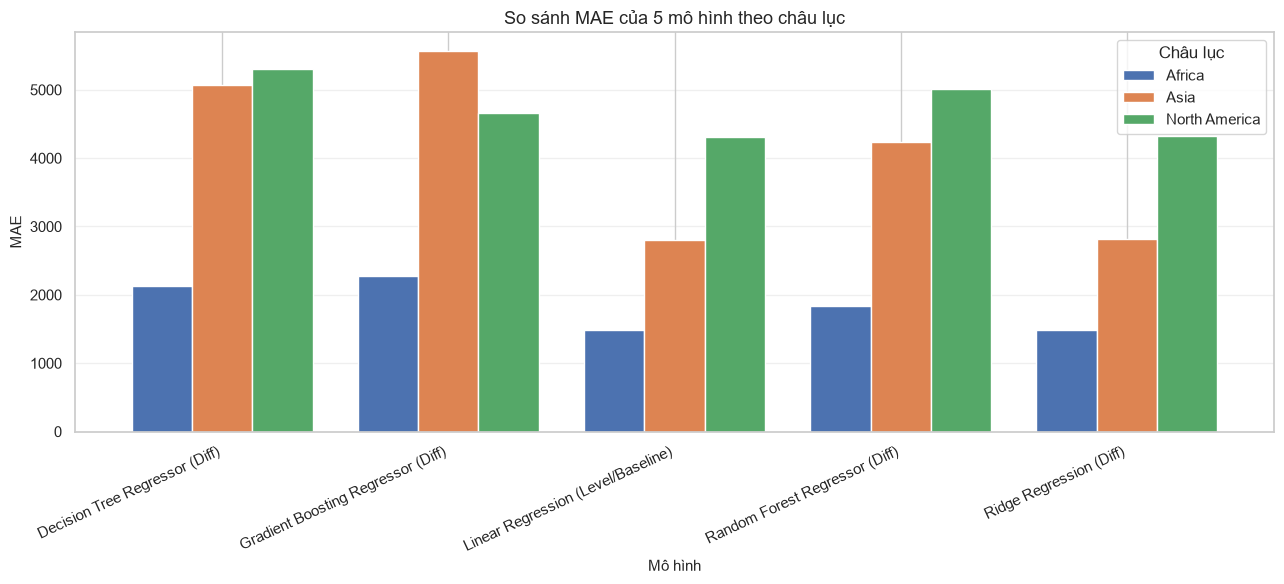

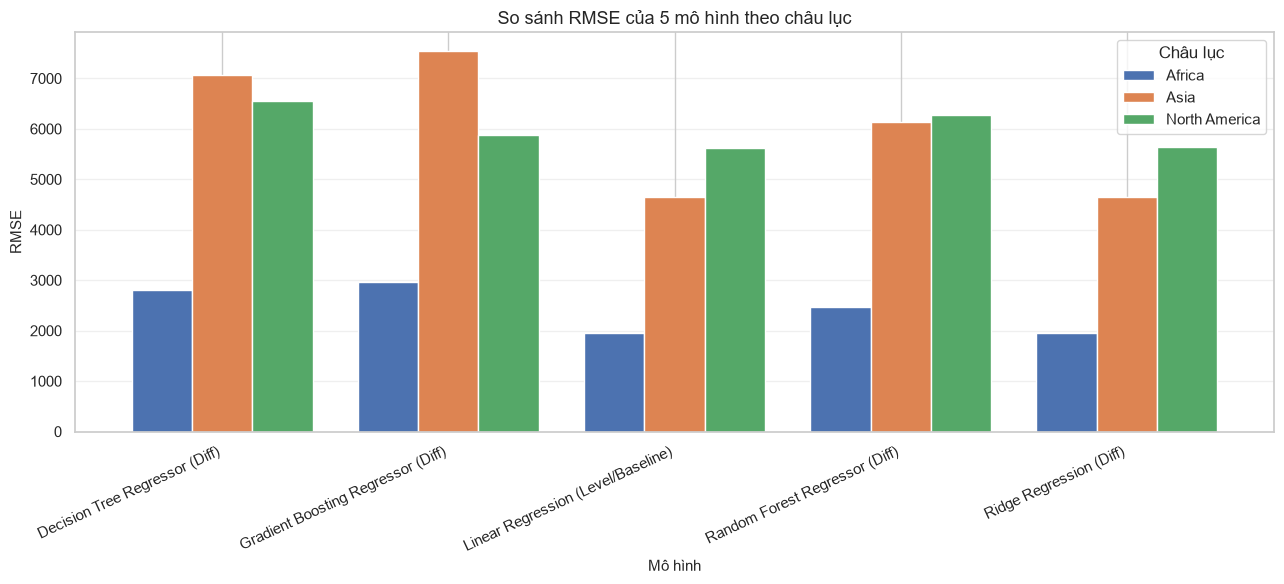

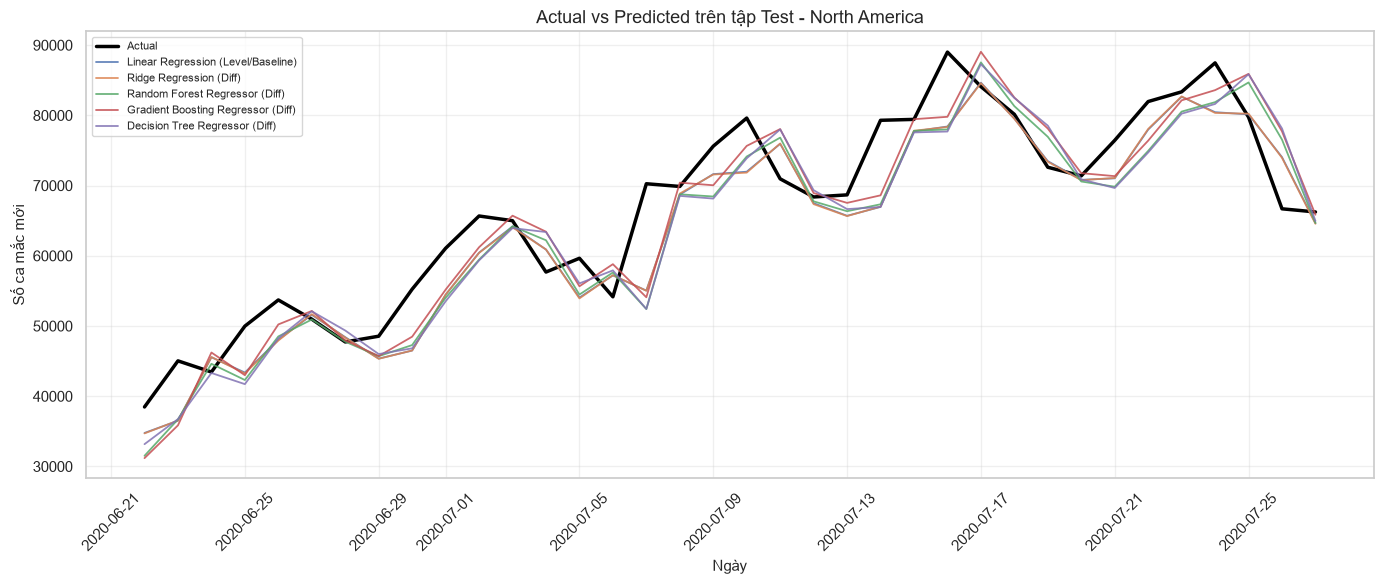

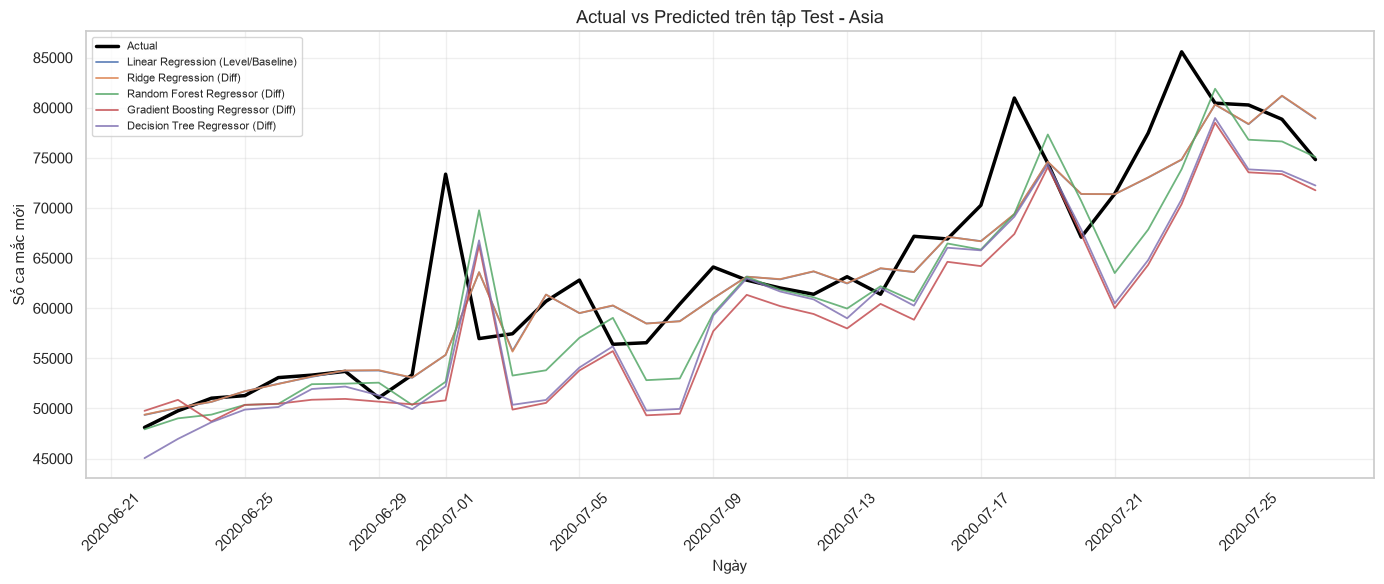

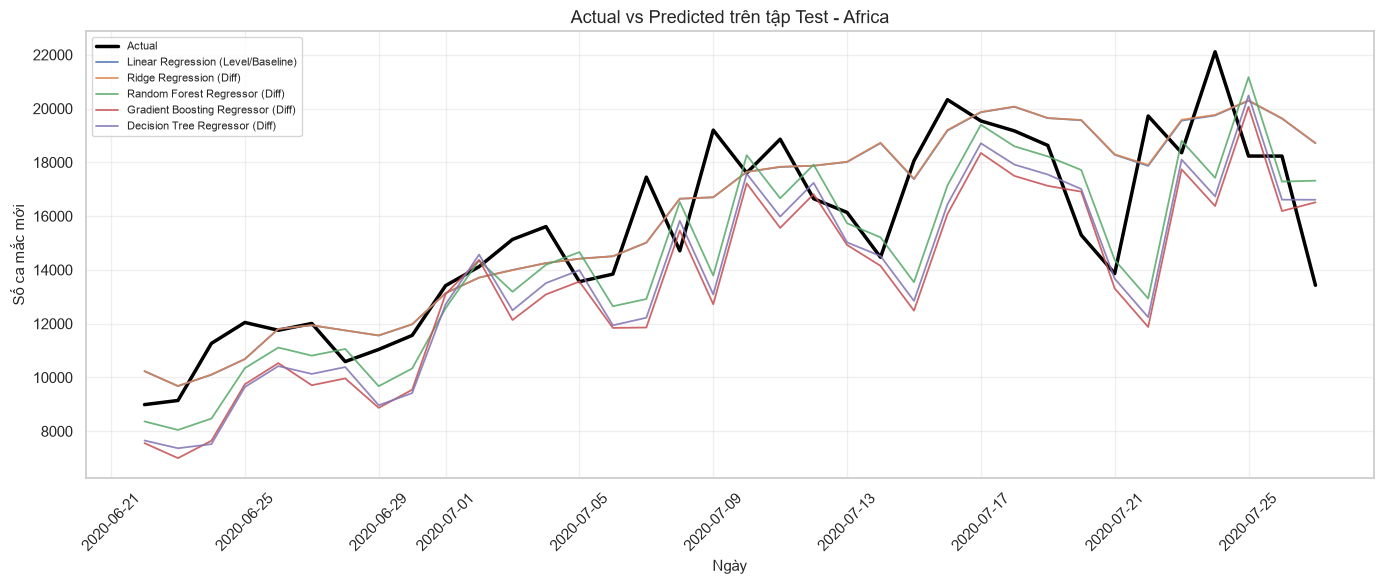


XẾP HẠNG MÔ HÌNH THEO TỪNG CHÂU LỤC


,Continent,Model,MAE,RMSE,R2,MAPE (%),Rank_MAE,Rank_RMSE,Rank_R2,Mean_Rank
0,Africa,Linear Regression (Level/Baseline),"1,483.790","1,954.025",0.6636,9.83,1,1,1,1.00
1,Africa,Ridge Regression (Diff),"1,484.462","1,956.520",0.6627,9.84,2,2,2,2.00
2,Africa,Random Forest Regressor (Diff),"1,842.481","2,459.189",0.4671,11.63,3,3,3,3.00
3,Africa,Decision Tree Regressor (Diff),"2,126.889","2,799.796",0.3093,13.64,4,4,4,4.00
4,Africa,Gradient Boosting Regressor (Diff),"2,268.592","2,969.596",0.2230,14.49,5,5,5,5.00
5,Asia,Ridge Regression (Diff),"2,810.435","4,646.946",0.7945,4.11,2,1,1,1.33
6,Asia,Linear Regression (Level/Baseline),"2,804.360","4,647.228",0.7945,4.10,1,2,2,1.67
7,Asia,Random Forest Regressor (Diff),"4,230.010","6,127.835",0.6427,6.33,3,3,3,3.00
8,Asia,Decision Tree Regressor (Diff),"5,076.491","7,062.702",0.5253,7.63,4,4,4,4.00
9,Asia,Gradient Boosting Regressor (Diff),"5,562.272","7,536.662",0.4594,8.31,5,5,5,5.00



MÔ HÌNH ĐƯỢC CHỌN CHO TỪNG CHÂU LỤC


,Continent,Model,MAE,RMSE,R2,MAPE (%),Mean_Rank
0,Africa,Linear Regression (Level/Baseline),"1,483.790","1,954.025",0.6636,9.83,1.00
1,Asia,Ridge Regression (Diff),"2,810.435","4,646.946",0.7945,4.11,1.33
2,North America,Linear Regression (Level/Baseline),"4,303.504","5,626.058",0.8249,6.71,1.00



Africa: chọn Linear Regression (Level/Baseline).
MAE = 1483.790; RMSE = 1954.025; R2 = 0.6636; MAPE = 9.83%.
Thứ hạng trung bình của mô hình: 1.00 (càng thấp càng tốt).

Asia: chọn Ridge Regression (Diff).
MAE = 2810.435; RMSE = 4646.946; R2 = 0.7945; MAPE = 4.11%.
Thứ hạng trung bình của mô hình: 1.33 (càng thấp càng tốt).

North America: chọn Linear Regression (Level/Baseline).
MAE = 4303.504; RMSE = 5626.058; R2 = 0.8249; MAPE = 6.71%.
Thứ hạng trung bình của mô hình: 1.00 (càng thấp càng tốt).

Kết luận phương pháp: mô hình được chọn dựa trên thứ hạng kết hợp MAE, RMSE và R2. MAPE được dùng làm chỉ số bổ sung và cần được diễn giải thận trọng khi số ca thực tế bằng 0 hoặc gần 0.


In [9]:

# PHẦN 6 - ĐÁNH GIÁ VÀ SO SÁNH 5 MÔ HÌNH
# Sử dụng predictions được tạo ở Phần 5.
# Không huấn luyện lại mô hình trong phần này.

# ============================================================
# 1. KIỂM TRA DỮ LIỆU ĐẦU VÀO
# ============================================================

required_columns = [
    "Date", "Continent", "Model", "Actual", "Predicted"
]

missing_columns = [
    col for col in required_columns
    if col not in predictions.columns
]

if missing_columns:
    raise ValueError(
        f"Thiếu cột trong predictions: {missing_columns}. "
        "Hãy chạy Phần 5 trước Phần 6."
    )

if predictions.empty:
    raise ValueError("Bảng predictions đang rỗng.")

predictions = predictions.copy()
predictions["Date"] = pd.to_datetime(
    predictions["Date"], errors="coerce"
)
predictions["Actual"] = pd.to_numeric(
    predictions["Actual"], errors="coerce"
)
predictions["Predicted"] = pd.to_numeric(
    predictions["Predicted"], errors="coerce"
)

# Loại các dòng thiếu dữ liệu hoặc có giá trị vô hạn.
predictions = predictions.replace(
    [np.inf, -np.inf], np.nan
)
predictions = predictions.dropna(
    subset=required_columns
).copy()

if predictions.empty:
    raise ValueError(
        "Không còn dữ liệu hợp lệ để đánh giá."
    )

print("Số dòng dự báo hợp lệ:", len(predictions))
print("Các châu lục:", predictions["Continent"].unique())
print("Số mô hình:", predictions["Model"].nunique())


# ============================================================
# 2. HÀM TÍNH MAE, RMSE, R2 VÀ MAPE AN TOÀN
# ============================================================

def calculate_metrics(actual, predicted):
    """
    MAE: sai số tuyệt đối trung bình, càng thấp càng tốt.
    RMSE: căn bậc hai của sai số bình phương trung bình,
          càng thấp càng tốt.
    R2: hệ số xác định, thường càng gần 1 càng tốt.
    MAPE: sai số phần trăm tuyệt đối trung bình.

    MAPE chỉ tính trên những giá trị Actual khác 0
    và đủ xa 0 để phép chia có ý nghĩa.
    """

    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)

    # Chỉ sử dụng các cặp giá trị hữu hạn.
    valid = np.isfinite(actual) & np.isfinite(predicted)
    actual = actual[valid]
    predicted = predicted[valid]

    if len(actual) == 0:
        return {
            "MAE": np.nan,
            "RMSE": np.nan,
            "R2": np.nan,
            "MAPE (%)": np.nan,
            "MAPE valid (%)": 0.0,
            "MAPE excluded": 0,
            "N": 0,
        }

    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))

    # R2 không có ý nghĩa khi tập đánh giá có dưới 2 mẫu.
    if len(actual) >= 2:
        r2 = r2_score(actual, predicted)
    else:
        r2 = np.nan

    # Loại các giá trị Actual bằng 0 hoặc gần 0.
    # Ngưỡng 1e-8 tránh chia cho 0 do sai số số học.
    epsilon = 1e-8
    mape_mask = np.abs(actual) > epsilon

    if mape_mask.any():
        mape = np.mean(
            np.abs(
                (actual[mape_mask] - predicted[mape_mask])
                / actual[mape_mask]
            )
        ) * 100
    else:
        mape = np.nan

    excluded = int((~mape_mask).sum())
    valid_percentage = mape_mask.mean() * 100

    return {
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2,
        "MAPE (%)": mape,
        "MAPE valid (%)": valid_percentage,
        "MAPE excluded": excluded,
        "N": len(actual),
    }


# ============================================================
# 3. TÍNH METRICS CHO TỪNG MÔ HÌNH VÀ TỪNG CHÂU LỤC
# ============================================================

metrics_rows = []

for (continent, model_name), group in predictions.groupby(
    ["Continent", "Model"], sort=False
):
    result = calculate_metrics(
        group["Actual"],
        group["Predicted"]
    )

    metrics_rows.append({
        "Continent": continent,
        "Model": model_name,
        **result,
    })

metrics_df = pd.DataFrame(metrics_rows)

# Sắp xếp bảng theo mô hình trước, rồi theo châu lục.
# Giữ thứ tự mô hình thống nhất với Phần 5.
model_order = [
    "Linear Regression (Level/Baseline)",
    "Ridge Regression (Diff)",
    "Random Forest Regressor (Diff)",
    "Gradient Boosting Regressor (Diff)",
    "Decision Tree Regressor (Diff)",
]
continent_order = ["Africa", "Asia", "North America"]

model_rank = {name: rank for rank, name in enumerate(model_order)}
continent_rank = {
    name: rank for rank, name in enumerate(continent_order)
}

metrics_df["_model_order"] = metrics_df["Model"].map(model_rank).fillna(len(model_order))
metrics_df["_continent_order"] = metrics_df["Continent"].map(continent_rank).fillna(len(continent_order))
metrics_df = (
    metrics_df.sort_values(["_model_order", "_continent_order"])
    .drop(columns=["_model_order", "_continent_order"])
    .reset_index(drop=True)
)

print("\nBẢNG ĐÁNH GIÁ TỔNG HỢP CÁC MÔ HÌNH")
display(
    metrics_df.style.format({
        "MAE": "{:,.3f}",
        "RMSE": "{:,.3f}",
        "R2": "{:.4f}",
        "MAPE (%)": "{:.2f}",
        "MAPE valid (%)": "{:.1f}",
        "MAPE excluded": "{:.0f}",
        "N": "{:.0f}",
    }, na_rep="N/A")
)

print(
    "\nLưu ý: MAPE được tính trên các mẫu có Actual khác 0 "
    "và có trị tuyệt đối lớn hơn 1e-8."
)
print(
    "Cột MAPE excluded cho biết số mẫu bị loại khỏi phép tính MAPE."
)


# ============================================================
# 4. VẼ BIỂU ĐỒ SO SÁNH MAE VÀ RMSE
# ============================================================

for metric in ["MAE", "RMSE"]:
    pivot_metric = metrics_df.pivot(
        index="Model",
        columns="Continent",
        values=metric
    )

    ax = pivot_metric.plot(
        kind="bar",
        figsize=(13, 6),
        width=0.8
    )

    ax.set_title(
        f"So sánh {metric} của 5 mô hình theo châu lục"
    )
    ax.set_xlabel("Mô hình")
    ax.set_ylabel(metric)
    ax.legend(title="Châu lục")
    ax.grid(axis="y", alpha=0.3)

    plt.xticks(rotation=25, ha="right")
    plt.tight_layout()
    plt.show()


# ============================================================
# 5. VẼ ACTUAL VS PREDICTED TRÊN TẬP TEST
# ============================================================

for continent in predictions["Continent"].unique():

    continent_data = predictions.loc[
        predictions["Continent"] == continent
    ].copy()

    # Mỗi mô hình chỉ cần một đường Actual chung.
    actual_data = (
        continent_data[
            ["Date", "Actual"]
        ]
        .drop_duplicates()
        .sort_values("Date")
    )

    fig, ax = plt.subplots(figsize=(14, 6))

    ax.plot(
        actual_data["Date"],
        actual_data["Actual"],
        label="Actual",
        color="black",
        linewidth=2.5
    )

    for model_name in continent_data["Model"].unique():

        model_data = (
            continent_data.loc[
                continent_data["Model"] == model_name
            ]
            .sort_values("Date")
        )

        ax.plot(
            model_data["Date"],
            model_data["Predicted"],
            label=model_name,
            linewidth=1.3,
            alpha=0.85
        )

    ax.set_title(
        f"Actual vs Predicted trên tập Test - {continent}"
    )
    ax.set_xlabel("Ngày")
    ax.set_ylabel("Số ca mắc mới")
    ax.legend(loc="best", fontsize=8)
    ax.grid(True, alpha=0.3)

    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()


# ============================================================
# 6. CHỌN MÔ HÌNH TỐT NHẤT CHO TỪNG CHÂU LỤC
# ============================================================

# Xếp hạng từng chỉ số:
# MAE thấp hơn tốt hơn.
# RMSE thấp hơn tốt hơn.
# R2 cao hơn tốt hơn.
#
# Dùng trung bình thứ hạng của 3 chỉ số để hạn chế
# việc chọn mô hình chỉ dựa vào một chỉ số đơn lẻ.

rank_df = metrics_df.copy()

rank_df["Rank_MAE"] = (
    rank_df.groupby("Continent")["MAE"]
    .rank(method="min", ascending=True)
)

rank_df["Rank_RMSE"] = (
    rank_df.groupby("Continent")["RMSE"]
    .rank(method="min", ascending=True)
)

rank_df["Rank_R2"] = (
    rank_df.groupby("Continent")["R2"]
    .rank(method="min", ascending=False)
)

rank_columns = ["Rank_MAE", "Rank_RMSE", "Rank_R2"]

rank_df["Mean_Rank"] = rank_df[rank_columns].mean(axis=1)

rank_df = rank_df.sort_values(
    ["Continent", "Mean_Rank", "MAE"]
).reset_index(drop=True)

print("\nXẾP HẠNG MÔ HÌNH THEO TỪNG CHÂU LỤC")
display(
    rank_df[
        [
            "Continent", "Model",
            "MAE", "RMSE", "R2", "MAPE (%)",
            "Rank_MAE", "Rank_RMSE", "Rank_R2",
            "Mean_Rank"
        ]
    ].style.format({
        "MAE": "{:,.3f}",
        "RMSE": "{:,.3f}",
        "R2": "{:.4f}",
        "MAPE (%)": "{:.2f}",
        "Rank_MAE": "{:.0f}",
        "Rank_RMSE": "{:.0f}",
        "Rank_R2": "{:.0f}",
        "Mean_Rank": "{:.2f}",
    }, na_rep="N/A")
)

# Chọn mô hình có Mean_Rank thấp nhất trong từng châu lục.
best_rows = (
    rank_df.dropna(subset=["Mean_Rank"])
    .sort_values(["Continent", "Mean_Rank", "MAE"])
    .groupby("Continent", as_index=False)
    .first()
)

print("\nMÔ HÌNH ĐƯỢC CHỌN CHO TỪNG CHÂU LỤC")

if best_rows.empty:
    print("Chưa đủ chỉ số hợp lệ để chọn mô hình.")
else:
    display(
        best_rows[
            [
                "Continent", "Model",
                "MAE", "RMSE", "R2", "MAPE (%)",
                "Mean_Rank"
            ]
        ].style.format({
            "MAE": "{:,.3f}",
            "RMSE": "{:,.3f}",
            "R2": "{:.4f}",
            "MAPE (%)": "{:.2f}",
            "Mean_Rank": "{:.2f}",
        }, na_rep="N/A")
    )

    for _, row in best_rows.iterrows():
        print(
            f"\n{row['Continent']}: chọn {row['Model']}."
        )
        print(
            f"MAE = {row['MAE']:.3f}; "
            f"RMSE = {row['RMSE']:.3f}; "
            f"R2 = {row['R2']:.4f}; "
            f"MAPE = "
            f"{row['MAPE (%)']:.2f}%."
            if pd.notna(row["MAPE (%)"])
            else
            f"MAE = {row['MAE']:.3f}; "
            f"RMSE = {row['RMSE']:.3f}; "
            f"R2 = {row['R2']:.4f}; "
            "MAPE không khả dụng."
        )
        print(
            f"Thứ hạng trung bình của mô hình: "
            f"{row['Mean_Rank']:.2f} "
            "(càng thấp càng tốt)."
        )

print(
    "\nKết luận phương pháp: mô hình được chọn dựa trên thứ hạng "
    "kết hợp MAE, RMSE và R2. MAPE được dùng làm chỉ số bổ sung "
    "và cần được diễn giải thận trọng khi số ca thực tế bằng 0 "
    "hoặc gần 0."
)


# PHẦN 6. ĐÁNH GIÁ VÀ SO SÁNH MÔ HÌNH

## 6.1. Mục tiêu đánh giá

Sau khi huấn luyện các mô hình ở Phần 5, nhóm tiến hành đánh giá và so sánh hiệu quả dự báo số ca mắc COVID-19 trên tập kiểm tra (Test) cho ba châu lục: Châu Phi, Châu Á và Bắc Mỹ.

Các mục tiêu chính bao gồm:

- Tính toán các chỉ số MAE, RMSE, \(R^2\) và MAPE để đánh giá sai số dự báo.
- Tổng hợp kết quả của năm mô hình thành bảng so sánh theo từng châu lục.
- Trực quan hóa kết quả bằng biểu đồ so sánh MAE, RMSE và biểu đồ Actual vs Predicted.
- Lựa chọn mô hình phù hợp nhất cho từng châu lục dựa trên nhiều chỉ số đánh giá.

## 6.2. Các chỉ số đánh giá

Nhóm sử dụng bốn chỉ số để đánh giá chất lượng dự báo:

- **MAE (Mean Absolute Error):** Sai số tuyệt đối trung bình giữa giá trị thực tế và giá trị dự báo. MAE càng thấp thì dự báo càng gần với giá trị thực tế.
- **RMSE (Root Mean Squared Error):** Căn bậc hai của sai số bình phương trung bình. Chỉ số này nhạy hơn với những sai số lớn, vì vậy RMSE càng thấp càng tốt.
- **\(R^2\) (Coefficient of Determination):** Hệ số xác định, phản ánh mức độ mô hình giải thích sự biến thiên của dữ liệu. Giá trị càng gần 1 thường cho thấy mô hình phù hợp hơn; \(R^2\) âm vẫn có thể xuất hiện khi mô hình dự báo kém.
- **MAPE (Mean Absolute Percentage Error):** Sai số phần trăm tuyệt đối trung bình, giúp biểu diễn sai số tương đối giữa giá trị thực tế và giá trị dự báo.

Đối với MAPE, các mẫu có giá trị thực tế bằng 0 hoặc gần 0 được loại khỏi phép tính nhằm tránh phép chia không ổn định. Do đó, cần xem xét số lượng mẫu hợp lệ khi diễn giải chỉ số này.

## 6.3. Bảng tổng hợp kết quả

Kết quả đánh giá được tổng hợp theo từng mô hình và từng châu lục, bao gồm MAE, RMSE, \(R^2\), MAPE và số lượng mẫu được sử dụng.

Bảng tổng hợp giúp nhận biết sự khác biệt về hiệu quả dự báo giữa các mô hình, đồng thời cho phép so sánh khả năng dự báo của từng mô hình trên các khu vực khác nhau.

Khi phân tích kết quả, MAE và RMSE được sử dụng để đánh giá độ lớn của sai số; \(R^2\) phản ánh mức độ phù hợp của mô hình; còn MAPE cung cấp thêm góc nhìn về sai số tương đối.

## 6.4. So sánh mô hình bằng biểu đồ

Nhóm sử dụng biểu đồ cột để so sánh MAE và RMSE của các mô hình trên từng châu lục.

- Mô hình có MAE thấp cho thấy sai lệch tuyệt đối trung bình nhỏ.
- Mô hình có RMSE thấp cho thấy sai số lớn được hạn chế tốt hơn.
- Sự khác biệt giữa MAE và RMSE có thể giúp nhận biết ảnh hưởng của các sai số dự báo lớn.

Ngoài ra, biểu đồ **Actual vs Predicted** được xây dựng trên tập Test cho từng châu lục. Giá trị thực tế được so sánh với giá trị dự báo theo thời gian. Nếu đường dự báo bám sát xu hướng và biến động của đường thực tế, mô hình có khả năng mô phỏng diễn biến dữ liệu tốt hơn.

## 6.5. Lựa chọn mô hình tốt nhất

Mô hình phù hợp nhất được lựa chọn riêng cho từng châu lục dựa trên sự kết hợp của MAE, RMSE và \(R^2\), thay vì chỉ dựa vào một chỉ số duy nhất.

Trong phần phân tích, nhóm sử dụng thứ hạng của từng chỉ số: MAE và RMSE có thứ hạng tốt hơn khi giá trị thấp hơn, trong khi \(R^2\) có thứ hạng tốt hơn khi giá trị cao hơn. Thứ hạng trung bình càng thấp thì mô hình càng được ưu tiên theo phương pháp này.

MAPE được sử dụng như một chỉ số bổ sung để đánh giá sai số tương đối. Khi diễn giải kết quả, cần lưu ý rằng MAPE có thể không đại diện đầy đủ cho toàn bộ tập Test nếu có nhiều giá trị thực tế bằng 0 hoặc gần 0.

## 6.6. Kết luận

Thông qua các chỉ số định lượng và biểu đồ trực quan, nhóm tiến hành so sánh hiệu quả của năm mô hình dự báo trên ba châu lục. Kết quả giúp xác định mô hình phù hợp nhất cho từng khu vực và đánh giá khả năng dự báo số ca mắc COVID-19 trên dữ liệu chưa được sử dụng để huấn luyện.

Mô hình được lựa chọn cuối cùng cần được nhận xét dựa trên các giá trị MAE, RMSE, \(R^2\), MAPE và hình dạng đường Actual vs Predicted thu được từ kết quả chạy thực tế. Việc kết hợp nhiều chỉ số giúp đưa ra đánh giá toàn diện hơn về hiệu quả dự báo của các mô hình.

## PHẦN 7. PHÂN TÍCH PHẦN DƯ VÀ DỰ BÁO NGẮN HẠN (NẾU ĐỦ THỜI GIAN)
7.1. Mục tiêu
Phần này kiểm tra sai số của mô hình được chọn ở Phần 6 trên tập Test và minh họa dự báo đệ quy trong 7 ngày kế tiếp. Việc phân tích phần dư giúp xem sai số có tập trung quanh 0 hay còn thiên lệch; dự báo ngắn hạn cho thấy cách mô hình sử dụng các giá trị dự báo trước đó để tạo đầu vào cho bước tiếp theo.

7.2. Phân tích phần dư
Phần dư được tính theo công thức:
\[
 e_t = Actual_t - Predicted_t
\]
- Phần dư dương: mô hình dự báo thấp hơn giá trị thực tế (under-prediction).
- Phần dư âm: mô hình dự báo cao hơn giá trị thực tế (over-prediction).
- Phần dư quanh 0 và không có cấu trúc rõ rệt thường là dấu hiệu tốt hơn; tuy nhiên histogram và đồ thị theo thời gian chỉ là chẩn đoán, không chứng minh mô hình đã nắm bắt toàn bộ cấu trúc chuỗi.
Mô hình được chọn riêng cho từng châu lục theo bảng xếp hạng ở Phần 6, không áp dụng một mô hình duy nhất cho tất cả khu vực.
7.3. Dự báo đệ quy 7 ngày
Để dự báo nhiều bước, tại mỗi ngày tương lai, code tạo các đặc trưng Lag và rolling từ dữ liệu lịch sử gần nhất. Sau khi dự báo ngày đầu tiên, giá trị dự báo được đưa trở lại chuỗi đầu vào để tạo Lag/rolling cho ngày kế tiếp; không dùng số ca thực tế tương lai.

Đây chỉ là thử nghiệm ngoại suy kỹ thuật từ dữ liệu lịch sử, không phải dự báo y tế/chính sách chính thức. Kết quả là dự báo điểm, không có khoảng tin cậy; sai số có thể tăng qua từng bước. Với mô hình Diff, dự báo sai phân được cộng với Lag_1 để trở lại mức New_Confirmed. Nếu kết quả dự báo mức ca nhỏ hơn 0, code giới hạn ở 0 vì số ca dự báo không thể âm; điều này cần được ghi nhận khi diễn giải.


MÔ HÌNH ĐƯỢC CHỌN VÀ THỐNG KÊ PHẦN DƯ TRÊN TEST


,Continent,Selected Model,N,Residual Mean,Residual Std,Residual MAE,Residual RMSE
0,Africa,Linear Regression (Level/Baseline),36,-494.376,"1,917.267","1,483.790","1,954.025"
1,Asia,Ridge Regression (Diff),36,851.468,"4,633.073","2,810.435","4,646.946"
2,North America,Linear Regression (Level/Baseline),36,"2,980.508","4,839.385","4,303.504","5,626.058"


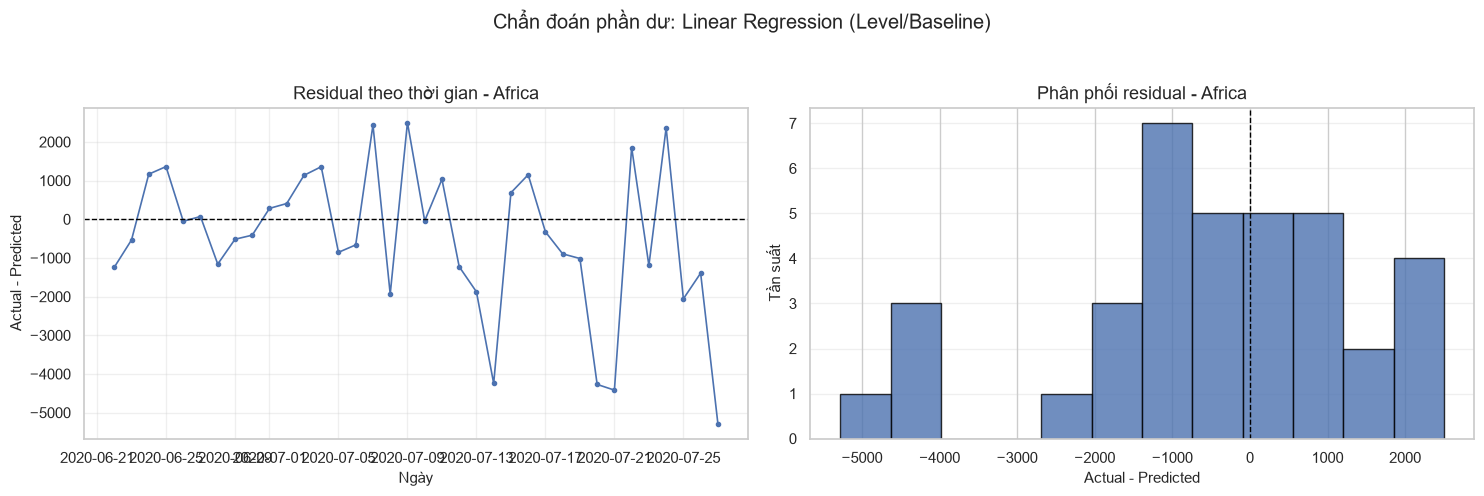

Nhận xét - Africa: residual trung bình = -494.376; trung bình dự báo cao hơn thực tế. Cần xem cả đồ thị theo thời gian và độ phân tán, không kết luận chỉ từ một thống kê đơn lẻ.


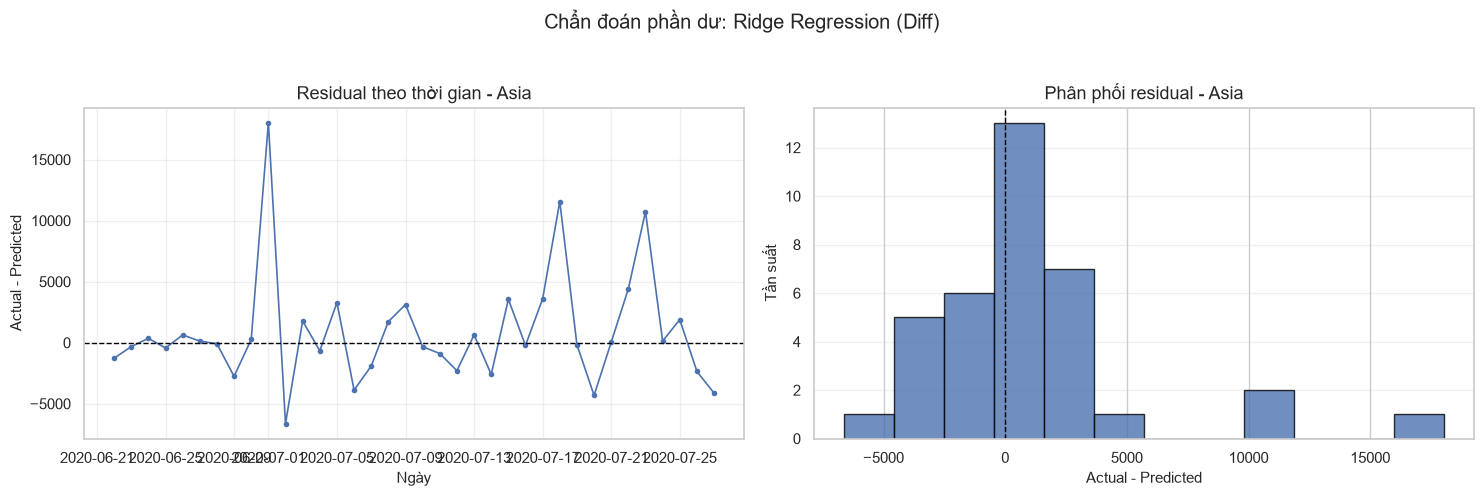

Nhận xét - Asia: residual trung bình = 851.468; trung bình dự báo thấp hơn thực tế. Cần xem cả đồ thị theo thời gian và độ phân tán, không kết luận chỉ từ một thống kê đơn lẻ.


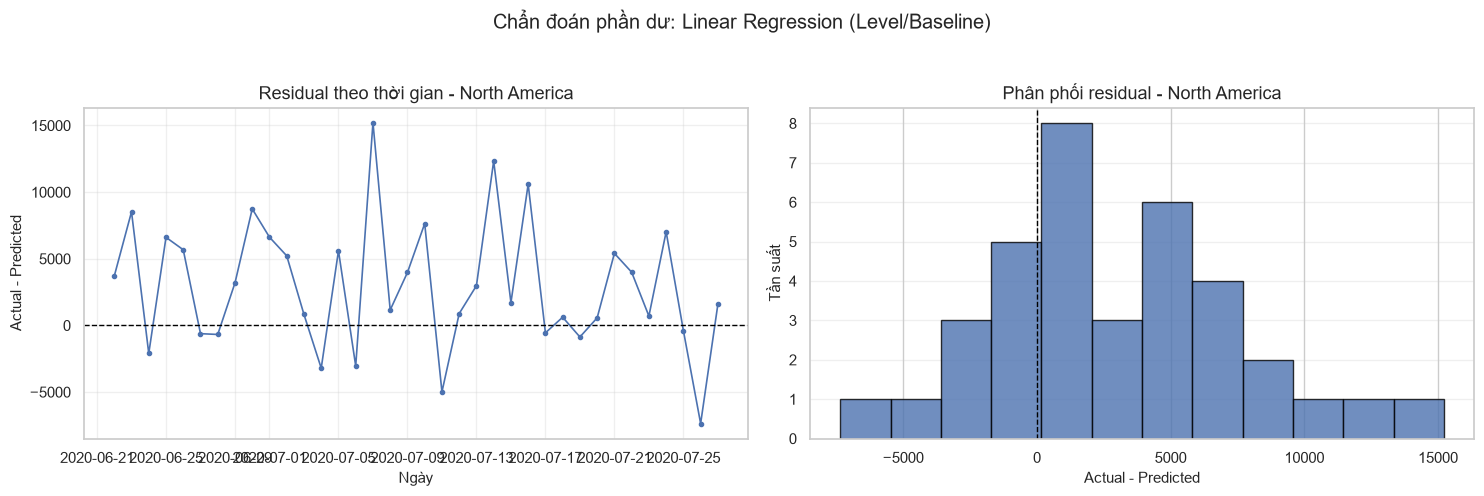

Nhận xét - North America: residual trung bình = 2,980.508; trung bình dự báo thấp hơn thực tế. Cần xem cả đồ thị theo thời gian và độ phân tán, không kết luận chỉ từ một thống kê đơn lẻ.
DỰ BÁO ĐỆ QUY 7 NGÀY - THỬ NGHIỆM NGOẠI SUY, KHÔNG PHẢI DỰ BÁO Y TẾ CHÍNH THỨC


,Date,Continent,Selected Model,Predicted New_Confirmed,Forecast Step
0,2020-07-28 00:00:00,Africa,Linear Regression (Level/Baseline),"15,515.50",1
1,2020-07-29 00:00:00,Africa,Linear Regression (Level/Baseline),"16,929.54",2
2,2020-07-30 00:00:00,Africa,Linear Regression (Level/Baseline),"19,107.03",3
3,2020-07-31 00:00:00,Africa,Linear Regression (Level/Baseline),"19,729.30",4
4,2020-08-01 00:00:00,Africa,Linear Regression (Level/Baseline),"19,349.25",5
5,2020-08-02 00:00:00,Africa,Linear Regression (Level/Baseline),"18,576.93",6
6,2020-08-03 00:00:00,Africa,Linear Regression (Level/Baseline),"16,969.87",7
7,2020-07-28 00:00:00,Asia,Ridge Regression (Diff),"79,576.74",1
8,2020-07-29 00:00:00,Asia,Ridge Regression (Diff),"83,334.93",2
9,2020-07-30 00:00:00,Asia,Ridge Regression (Diff),"84,017.60",3


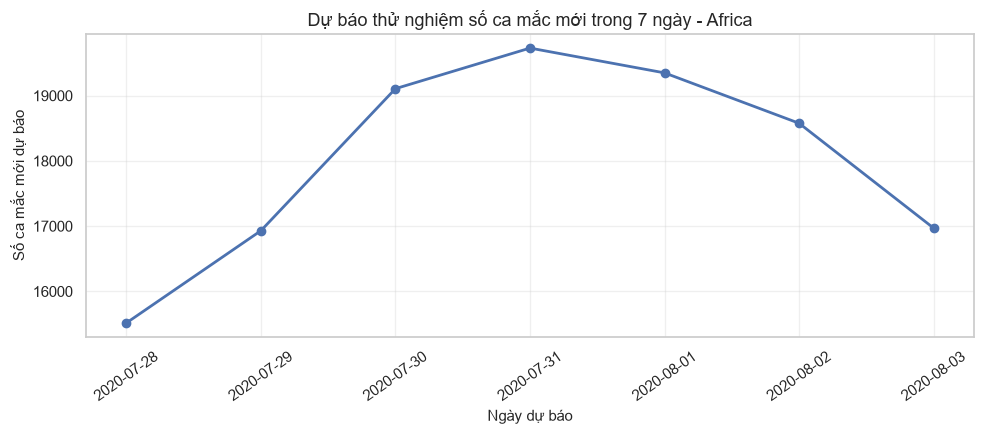

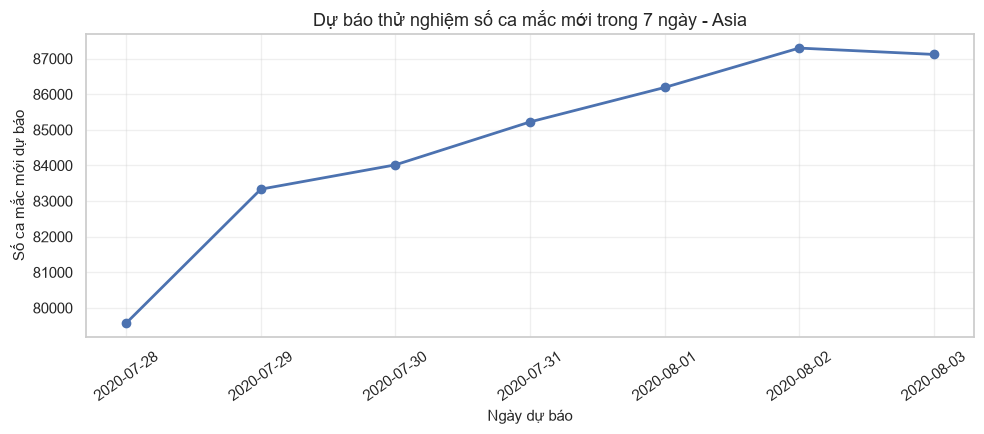

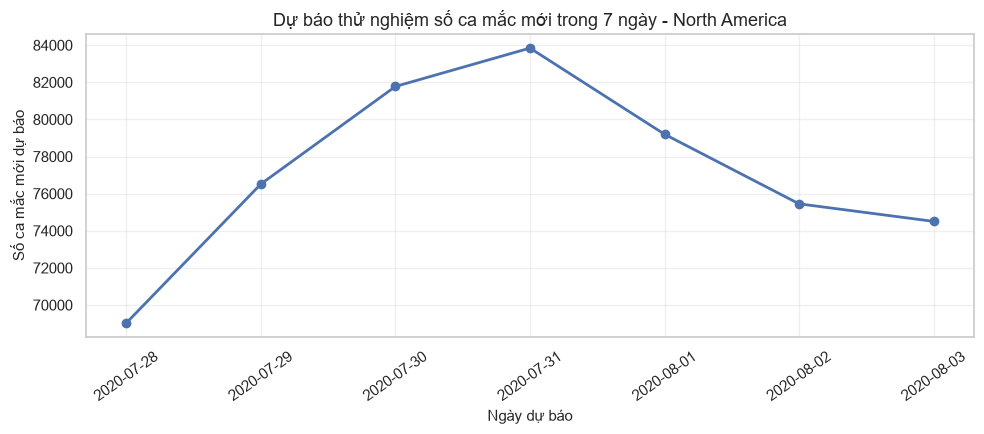

Lưu ý: mô hình được refit trên toàn bộ đặc trưng lịch sử sau khi đã chọn bằng Test. Từ bước 2 trở đi, Lag/rolling nhận cả dự báo của các bước trước; không sử dụng Actual tương lai. Đây là dự báo điểm mang tính minh họa và không có khoảng tin cậy.


In [13]:
# PHẦN 7 - PHÂN TÍCH PHẦN DƯ VÀ DỰ BÁO ĐỆ QUY 7 NGÀY
# Sử dụng predictions, best_rows, df, feat và cấu hình mô hình đã tạo ở Phần 1-6.
# Không đọc lại CSV và không dùng giá trị thực tế của các ngày dự báo tương lai.

required_p7_vars = [
    "predictions", "best_rows", "df", "feat", "continents",
    "FEATURES_ALL", "TARGET_LEVEL", "TARGET_DIFF", "make_models",
]
missing_p7_vars = [name for name in required_p7_vars if name not in globals()]
if missing_p7_vars:
    raise NameError(
        f"Thiếu biến {missing_p7_vars}. Hãy chạy notebook tuần tự từ Phần 1 đến Phần 6."
    )

if best_rows.empty:
    raise ValueError("Phần 6 chưa chọn được mô hình hợp lệ cho các châu lục.")

# ------------------------------------------------------------
# 1. Lấy dự báo của mô hình tốt nhất cho từng châu lục và tính residual
# ------------------------------------------------------------
residual_parts = []
selected_model_map = {}
for _, selected_row in best_rows.iterrows():
    continent = selected_row["Continent"]
    model_name = selected_row["Model"]
    selected_model_map[continent] = model_name

    selected_predictions = predictions.loc[
        (predictions["Continent"] == continent)
        & (predictions["Model"] == model_name),
        ["Date", "Continent", "Model", "Actual", "Predicted"],
    ].copy()

    if selected_predictions.empty:
        print(f"Không tìm thấy dự báo Test cho {continent} - {model_name}; bỏ qua phần dư.")
        continue

    selected_predictions["Residual"] = (
        selected_predictions["Actual"] - selected_predictions["Predicted"]
    )
    residual_parts.append(selected_predictions)

if not residual_parts:
    raise ValueError("Không có dự báo phù hợp để phân tích phần dư.")

residual_df = (
    pd.concat(residual_parts, ignore_index=True)
    .sort_values(["Continent", "Date"])
    .reset_index(drop=True)
)

residual_summary_rows = []
for (continent, model_name), group in residual_df.groupby(["Continent", "Model"]):
    residual_values = group["Residual"].to_numpy(dtype=float)
    residual_summary_rows.append({
        "Continent": continent,
        "Selected Model": model_name,
        "N": len(group),
        "Residual Mean": float(np.mean(residual_values)),
        "Residual Std": float(np.std(residual_values, ddof=1)) if len(residual_values) > 1 else np.nan,
        "Residual MAE": float(np.mean(np.abs(residual_values))),
        "Residual RMSE": float(np.sqrt(np.mean(residual_values ** 2))),
    })

residual_summary = pd.DataFrame(residual_summary_rows)
print("MÔ HÌNH ĐƯỢC CHỌN VÀ THỐNG KÊ PHẦN DƯ TRÊN TEST")
display(residual_summary.style.format({
    "Residual Mean": "{:,.3f}",
    "Residual Std": "{:,.3f}",
    "Residual MAE": "{:,.3f}",
    "Residual RMSE": "{:,.3f}",
    "N": "{:,.0f}",
}, na_rep="N/A"))

# Đồ thị phần dư theo thời gian và phân phối residual cho từng châu lục.
for continent in residual_df["Continent"].unique():
    temp = residual_df.loc[residual_df["Continent"] == continent].sort_values("Date")
    model_name = temp["Model"].iloc[0]

    fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))

    axes[0].plot(temp["Date"], temp["Residual"], marker="o", markersize=3, linewidth=1.2)
    axes[0].axhline(0, color="black", linestyle="--", linewidth=1)
    axes[0].set_title(f"Residual theo thời gian - {continent}")
    axes[0].set_xlabel("Ngày")
    axes[0].set_ylabel("Actual - Predicted")
    axes[0].grid(True, alpha=0.3)

    axes[1].hist(temp["Residual"], bins=12, edgecolor="black", alpha=0.8)
    axes[1].axvline(0, color="black", linestyle="--", linewidth=1)
    axes[1].set_title(f"Phân phối residual - {continent}")
    axes[1].set_xlabel("Actual - Predicted")
    axes[1].set_ylabel("Tần suất")
    axes[1].grid(axis="y", alpha=0.3)

    fig.suptitle(f"Chẩn đoán phần dư: {model_name}", y=1.03)
    plt.tight_layout()
    plt.show()

    mean_residual = temp["Residual"].mean()
    if mean_residual > 0:
        bias_text = "trung bình dự báo thấp hơn thực tế"
    elif mean_residual < 0:
        bias_text = "trung bình dự báo cao hơn thực tế"
    else:
        bias_text = "phần dư trung bình bằng 0"
    print(
        f"Nhận xét - {continent}: residual trung bình = {mean_residual:,.3f}; "
        f"{bias_text}. Cần xem cả đồ thị theo thời gian và độ phân tán, "
        "không kết luận chỉ từ một thống kê đơn lẻ."
    )

# ------------------------------------------------------------
# 2. Dự báo đệ quy 7 ngày tiếp theo
# ------------------------------------------------------------
# Chọn mô hình theo kết quả Test ở Phần 6 rồi fit lại mô hình đó trên toàn bộ
# feature history hiện có để minh họa dự báo sau ngày cuối dữ liệu.
# Việc refit không thay đổi kết quả đánh giá Test ở Phần 6.
FORECAST_HORIZON = 7
forecast_parts = []
forecast_models = {}

required_features = list(FEATURES_ALL)
needed_history = max(7, 2)  # cần ít nhất 7 ngày để tạo rolling mean/std

for continent, model_name in selected_model_map.items():
    if continent not in set(df["Continent"].dropna().unique()):
        print(f"Không tìm thấy dữ liệu lịch sử cho {continent}; bỏ qua dự báo.")
        continue

    full_features = (
        feat.loc[feat["Continent"] == continent]
        .sort_values("Date")
        .dropna(subset=[TARGET_LEVEL, TARGET_DIFF, *required_features])
        .copy()
    )
    if full_features.empty:
        print(f"Không có feature hợp lệ để refit cho {continent}; bỏ qua dự báo.")
        continue

    model_mode, _ = make_models()[model_name]
    target_column = TARGET_LEVEL if model_mode == "level" else TARGET_DIFF
    forecast_model = make_models()[model_name][1]
    forecast_model.fit(
        full_features[required_features],
        full_features[target_column].astype(float),
    )
    forecast_models[continent] = {
        "model_name": model_name,
        "target_mode": model_mode,
        "model": forecast_model,
    }

    historical = (
        df.loc[df["Continent"] == continent, ["Date", "New_Confirmed"]]
        .dropna(subset=["Date", "New_Confirmed"])
        .sort_values("Date")
        .drop_duplicates(subset=["Date"], keep="last")
    )
    history_values = historical["New_Confirmed"].astype(float).tolist()
    if len(history_values) < needed_history:
        print(f"Không đủ lịch sử gần nhất để dự báo 7 ngày cho {continent}; bỏ qua.")
        continue

    last_date = pd.to_datetime(historical["Date"].max())
    recent_values = list(history_values)
    region_forecasts = []

    for step in range(1, FORECAST_HORIZON + 1):
        future_date = last_date + pd.Timedelta(days=step)
        # Các lag/rolling chỉ lấy từ giá trị lịch sử và dự báo đã sinh ở bước trước.
        features_for_day = {
            "Lag_1": recent_values[-1],
            "Lag_2": recent_values[-2],
            "Lag_3": recent_values[-3],
            "Lag_7": recent_values[-7],
            "Roll_Mean_7": float(np.mean(recent_values[-7:])),
            "Roll_Std_7": float(np.std(recent_values[-7:], ddof=1)),
            "DayOfWeek": int(future_date.dayofweek),
            "IsWeekend": int(future_date.dayofweek >= 5),
            "Month": int(future_date.month),
        }
        X_future = pd.DataFrame([features_for_day], columns=required_features)
        predicted_value = float(forecast_model.predict(X_future)[0])

        if model_mode == "diff":
            predicted_cases = predicted_value + recent_values[-1]
        else:
            predicted_cases = predicted_value

        # Số ca mắc mới không thể âm; ghi nhận giới hạn này khi diễn giải dự báo.
        predicted_cases = max(0.0, predicted_cases)
        recent_values.append(predicted_cases)  # đệ quy: dùng forecast này cho bước kế tiếp
        region_forecasts.append({
            "Date": future_date,
            "Continent": continent,
            "Selected Model": model_name,
            "Predicted New_Confirmed": predicted_cases,
            "Forecast Step": step,
        })

    forecast_parts.extend(region_forecasts)

if forecast_parts:
    forecast_7d = pd.DataFrame(forecast_parts)
    print(
        "DỰ BÁO ĐỆ QUY 7 NGÀY - THỬ NGHIỆM NGOẠI SUY, "
        "KHÔNG PHẢI DỰ BÁO Y TẾ CHÍNH THỨC"
    )
    display(forecast_7d.style.format({
        "Predicted New_Confirmed": "{:,.2f}",
        "Forecast Step": "{:.0f}",
    }))

    for continent in forecast_7d["Continent"].unique():
        temp = forecast_7d.loc[forecast_7d["Continent"] == continent].sort_values("Date")
        fig, ax = plt.subplots(figsize=(10, 4.5))
        ax.plot(temp["Date"], temp["Predicted New_Confirmed"], marker="o", linewidth=2)
        ax.set_title(f"Dự báo thử nghiệm số ca mắc mới trong 7 ngày - {continent}")
        ax.set_xlabel("Ngày dự báo")
        ax.set_ylabel("Số ca mắc mới dự báo")
        ax.grid(True, alpha=0.3)
        plt.xticks(rotation=35)
        plt.tight_layout()
        plt.show()
else:
    forecast_7d = pd.DataFrame(columns=[
        "Date", "Continent", "Selected Model", "Predicted New_Confirmed", "Forecast Step"
    ])
    print("Chưa tạo được bảng forecast_7d; kiểm tra dữ liệu history và mô hình đã chọn.")

print(
    "Lưu ý: mô hình được refit trên toàn bộ đặc trưng lịch sử sau khi đã chọn bằng Test. "
    "Từ bước 2 trở đi, Lag/rolling nhận cả dự báo của các bước trước; không sử dụng "
    "Actual tương lai. Đây là dự báo điểm mang tính minh họa và không có khoảng tin cậy."
)

## PHẦN 8. KẾT LUẬN VÀ HẠN CHẾ
8.1. Tổng kết phân tích khám phá dữ liệu (EDA)
Phần 2 mô tả chuỗi ca mắc mới, trung bình trượt 7/14 ngày, số ca xác nhận tích lũy, đỉnh ca mắc mới quan sát được và mức ca mắc trung bình theo thứ trong tuần ở Bắc Mỹ, châu Á và châu Phi. Nhận xét định lượng cần dựa trên bảng/biểu đồ được tạo từ dữ liệu chạy thực tế; đỉnh cao nhất trong bộ dữ liệu không nhất thiết là đỉnh dịch ngoài đời thực.

8.2. Kết quả so sánh mô hình
Phần 6 đánh giá năm mô hình trên tập Test theo thời gian. Mô hình được ưu tiên riêng cho từng châu lục theo thứ hạng trung bình của MAE, RMSE và R². MAE/RMSE thấp hơn thường tốt hơn; R² cao hơn thường tốt hơn. MAPE là chỉ số bổ sung, được tính trên các mẫu có Actual khác 0 và đủ xa 0 theo ngưỡng trong code. Vì vậy cần đọc MAPE cùng số mẫu hợp lệ, không dùng riêng chỉ số này để quyết định.

Ô code ngay dưới phần Markdown này sinh phần tóm tắt dựa trên các kết quả thật của lần chạy notebook, gồm ngày và mức đỉnh quan sát được, mô hình được chọn cùng các chỉ số đánh giá.

8.3. Diễn giải phần dư và dự báo ngắn hạn
Phần 7 phân tích Residual = Actual - Predicted trên Test. Phần dư dương cho biết mô hình dự báo thấp hơn thực tế; phần dư âm cho biết dự báo cao hơn thực tế. Dự báo đệ quy 7 ngày là phép thử ngoại suy từ dữ liệu lịch sử: ở mỗi bước, các lag và rolling được cập nhật bằng dự báo trước đó, không sử dụng số ca thực tế trong tương lai.

8.4. Hạn chế
- Dữ liệu là chuỗi thời gian tổng hợp theo châu lục, nên kết quả có thể che khuất khác biệt giữa quốc gia, vùng lãnh thổ và thời điểm ghi nhận.
- New_Confirmed được tính bằng sai phân của số ca tích lũy; các giá trị âm có thể xuất hiện do điều chỉnh dữ liệu nguồn và không nên tự động coi là số ca âm theo nghĩa dịch tễ học.
- Mô hình sử dụng các đặc trưng lịch sử và lịch, chưa tích hợp dân số, xét nghiệm, tiêm chủng, biến thể virus, biện pháp y tế công cộng hay chất lượng báo cáo.
- Không thể dùng số ca tuyệt đối để kết luận khu vực nào có nguy cơ tương đối cao hơn nếu không chuẩn hóa theo dân số và các yếu tố liên quan.
- Hiệu quả trên một tập Test thời gian cụ thể không bảo đảm hiệu quả khi áp dụng cho giai đoạn khác; dự báo nhiều bước có thể tích lũy sai số và không có khoảng bất định trong phiên bản này.
- MAPE không ổn định khi giá trị thực tế bằng 0 hoặc gần 0; việc loại mẫu khỏi MAPE cần được nêu cùng số mẫu được tính.

8.5. Hướng cải thiện
Có thể mở rộng bằng cách đánh giá cuốn chiếu theo thời gian (rolling-origin validation), tinh chỉnh siêu tham số chỉ trên dữ liệu Train/Validation, so sánh với baseline đơn giản, kiểm tra tự tương quan của phần dư, báo cáo khoảng dự báo, và bổ sung dữ liệu theo dân số hoặc yếu tố dịch tễ phù hợp. Trước khi sử dụng ngoài mục đích học thuật, cần thẩm định chất lượng dữ liệu và đánh giá bởi chuyên gia có thẩm quyền.
Kết luận chung: Đây là bài thực hành phân tích chuỗi thời gian và so sánh mô hình học máy trên dữ liệu lịch sử COVID-19. Kết quả hỗ trợ học tập và mô tả dữ liệu; không thay thế đánh giá dịch tễ, tư vấn y tế hay dự báo chính thức.


In [14]:
# PHẦN 8 - TÓM TẮT KẾT QUẢ DỰA TRÊN LẦN CHẠY HIỆN TẠI
# Nội dung được sinh từ các biến đã tạo ở Phần 1, 2, 6 và 7; không tự điền số liệu giả.

print("=" * 78)
print("TÓM TẮT KẾT QUẢ COVID-19: NORTH AMERICA, ASIA VÀ AFRICA")
print("=" * 78)

# 1. Tóm tắt phạm vi dữ liệu và chất lượng chuỗi thời gian
if "df" in globals() and not df.empty:
    print(
        f"Khoảng thời gian phân tích: {pd.to_datetime(df['Date']).min().date()} "
        f"đến {pd.to_datetime(df['Date']).max().date()}."
    )
    for continent in continents:
        temp = df.loc[df["Continent"] == continent].sort_values("Date")
        if temp.empty:
            continue
        peak = temp.loc[temp["New_Confirmed"].idxmax()]
        print(
            f"- {continent}: {len(temp):,} ngày quan sát; "
            f"đỉnh New_Confirmed quan sát được là {peak['New_Confirmed']:,.0f} "
            f"vào {pd.to_datetime(peak['Date']).date()}."
        )

        # Tổng hợp số liệu tích lũy ở ngày cuối của từng châu lục.
        final_row = temp.iloc[-1]
        print(
            f"  Cuối chuỗi: Confirmed={final_row['Confirmed']:,.0f}; "
            f"Deaths={final_row['Deaths']:,.0f}; "
            f"Recovered={final_row['Recovered']:,.0f}."
        )
else:
    print("Không có biến df hợp lệ để tóm tắt EDA.")

# 2. Mô hình được chọn theo thứ hạng kết hợp ở Phần 6
if "best_rows" in globals() and not best_rows.empty:
    print("\nMÔ HÌNH ĐƯỢC CHỌN CHO TỪNG CHÂU LỤC (theo Mean_Rank):")
    for _, row in best_rows.iterrows():
        mape_text = (
            f"{row['MAPE (%)']:.2f}%"
            if "MAPE (%)" in row.index and pd.notna(row["MAPE (%)"])
            else "không khả dụng"
        )
        print(
            f"- {row['Continent']}: {row['Model']} | "
            f"MAE={row['MAE']:,.3f}; RMSE={row['RMSE']:,.3f}; "
            f"R²={row['R2']:.4f}; MAPE={mape_text}; "
            f"Mean_Rank={row['Mean_Rank']:.2f}."
        )
else:
    print("Chưa có bảng best_rows; hãy chạy Phần 6 trước khi kết luận mô hình.")

# 3. Tóm tắt chẩn đoán residual
if "residual_summary" in globals() and not residual_summary.empty:
    print("\nTÓM TẮT PHẦN DƯ TRÊN TEST:")
    for _, row in residual_summary.iterrows():
        if row["Residual Mean"] > 0:
            bias = "dự báo thấp hơn thực tế trung bình"
        elif row["Residual Mean"] < 0:
            bias = "dự báo cao hơn thực tế trung bình"
        else:
            bias = "residual trung bình bằng 0"
        print(
            f"- {row['Continent']} ({row['Selected Model']}): "
            f"Residual Mean={row['Residual Mean']:,.3f}; "
            f"Residual RMSE={row['Residual RMSE']:,.3f}; {bias}."
        )

# 4. Tóm tắt bảng dự báo đệ quy
if "forecast_7d" in globals() and not forecast_7d.empty:
    print("\nDỰ BÁO ĐỆ QUY 7 NGÀY (chỉ để minh họa):")
    for continent, group in forecast_7d.groupby("Continent"):
        group = group.sort_values("Date")
        print(
            f"- {continent}: từ {group['Date'].min().date()} đến "
            f"{group['Date'].max().date()}; "
            f"các giá trị dự báo dao động từ "
            f"{group['Predicted New_Confirmed'].min():,.2f} đến "
            f"{group['Predicted New_Confirmed'].max():,.2f} ca/ngày."
        )
    print(
        "Các giá trị này là dự báo điểm đệ quy, không kèm khoảng bất định; "
        "không sử dụng như dự báo chính thức."
    )
else:
    print("Chưa có dự báo 7 ngày; xem thông báo ở Phần 7.")

print("\nHẠN CHẾ CẦN GHI NHỚ:")
print("- Dữ liệu tổng hợp theo châu lục và số ca tuyệt đối chưa được chuẩn hóa theo dân số.")
print("- Các biến đầu vào chủ yếu là lag/rolling và đặc trưng lịch; chưa có biến dịch tễ bổ sung.")
print("- Kết quả phụ thuộc giai đoạn dữ liệu và cách ghi nhận; không thay thế dự báo y tế chính thức.")
print("- MAPE cần được đọc cùng tỷ lệ mẫu hợp lệ và số mẫu bị loại do Actual bằng/gần 0.")


TÓM TẮT KẾT QUẢ COVID-19: NORTH AMERICA, ASIA VÀ AFRICA
Khoảng thời gian phân tích: 2020-01-22 đến 2020-07-27.
- North America: 188 ngày quan sát; đỉnh New_Confirmed quan sát được là 89,010 vào 2020-07-16.
  Cuối chuỗi: Confirmed=5,058,816; Deaths=207,226; Recovered=1,754,456.
- Asia: 188 ngày quan sát; đỉnh New_Confirmed quan sát được là 85,583 vào 2020-07-23.
  Cuối chuỗi: Confirmed=4,788,295; Deaths=104,469; Recovered=3,473,508.
- Africa: 188 ngày quan sát; đỉnh New_Confirmed quan sát được là 22,111 vào 2020-07-24.
  Cuối chuỗi: Confirmed=860,537; Deaths=18,176; Recovered=506,229.

MÔ HÌNH ĐƯỢC CHỌN CHO TỪNG CHÂU LỤC (theo Mean_Rank):
- Africa: Linear Regression (Level/Baseline) | MAE=1,483.790; RMSE=1,954.025; R²=0.6636; MAPE=9.83%; Mean_Rank=1.00.
- Asia: Ridge Regression (Diff) | MAE=2,810.435; RMSE=4,646.946; R²=0.7945; MAPE=4.11%; Mean_Rank=1.33.
- North America: Linear Regression (Level/Baseline) | MAE=4,303.504; RMSE=5,626.058; R²=0.8249; MAPE=6.71%; Mean_Rank=1.00.

TÓM TẮT 